# План теста

На встрече 1 мы решили, стоит ли вообще тестировать изменение, и подобрали оптимальные α и n. Теперь составляем сам план теста: как устроен A/B-тест, что и в каком порядке мерить и как ускорить сам тест.

## Часть 1. Как устроен A/B-тест

Сначала соберём каркас: от гипотезы через метрику и критерий к решению, а затем выберем критерий под тип метрики.

In [ ]:
import time
from dataclasses import dataclass
from typing import Dict, List, Literal, Optional, Sequence, Tuple, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.stats as st
import seaborn as sns
import statsmodels.api as sm
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import PercentFormatter
from numpy.typing import NDArray
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from statsmodels.stats.proportion import proportion_confint
from tqdm import tqdm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

FloatArray = NDArray[np.float64]

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'
ALPHA = 0.05


def masked_mean_var(x: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Считает среднее, дисперсию и размер выборки по строкам x, учитывая только наблюдения из mask."""
    n = mask.sum(axis=1)
    mean = (x * mask).sum(axis=1) / n
    var = ((x ** 2 * mask).sum(axis=1) - n * mean ** 2) / (n - 1)
    return mean, var, n


def z_pvalue(delta: np.ndarray, se: np.ndarray) -> np.ndarray:
    """Возвращает двустороннее p-value для разницы delta со стандартной ошибкой se."""
    return 2 * stats.norm.sf(np.abs(delta / se))


def rate_with_ci(rejected: np.ndarray) -> tuple[float, float, float]:
    """Возвращает долю отклонений H0 и её 95% ДИ Уилсона."""
    low, high = proportion_confint(rejected.sum(), rejected.size, method='wilson')
    return float(rejected.mean()), float(low), float(high)


def plot_rates(ax: plt.Axes, rates: dict[str, np.ndarray], title: str, reference: float | None = ALPHA) -> None:
    """Рисует доли отклонений H0 с 95% ДИ: одна точка на метод."""
    names = list(rates)[::-1]
    values = np.array([rate_with_ci(rates[name]) for name in names])
    ax.errorbar(values[:, 0], names, xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                fmt='o', color=BLUE, capsize=4)
    if reference is not None:
        ax.axvline(reference, color=RED, linestyle='--', label=f'Заявленный уровень {reference:.0%}')
        ax.legend(loc='lower right')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_title(title)


def diff_p(a, b):
    """Разность средних b - a, её стандартная ошибка и p-value (критерий Уэлча)."""
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return delta, se, 2 * st.norm.sf(abs(delta / se))


def rel_effect(a, b):
    """Относительный эффект b/a - 1 и его стандартная ошибка (дельта-метод, независимые группы)."""
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return mb / ma - 1, np.sqrt(vb / ma ** 2 + va * mb ** 2 / ma ** 4)


def pct(x, digits=1):
    return f'{100 * x:+.{digits}f}%'


## Пайплайн тестирования гипотез

Эффективное научное исследование требует тщательно формализованного подхода. Этот процесс включает в себя ряд последовательных шагов, от первоначальной гипотезы до окончательного внедрения результатов, и предполагает сложную систему взаимодействия между различными командами.

В общем случае тестирование представляет из себя следующую цепочку событий:

```
1. Формулирование гипотезы
2. Прототипирование дизайна тестирования
3. Сбор данных
4. Анализ данных
5. Формулирование итогов гипотезы
6. Подтверждение/Опровержение тестируемой гипотезы
7. Внедрение/ Отказ от внедрения
```

1.  **Формулирование гипотезы**

Начальный этап любого исследования – это формулировка проверяемой гипотезы. Гипотеза должна быть максимально точно сформулирована, чтобы не вносить недопонимание в трактовке другим командам, которые также участвуют в процессе тестирования. Как минимум гипотеза должна содержать:

* Контекст, почему хотим вносить изменение
* Вносимое изменение
* Целевая аудитория
* Ожидаемый эффект

Например,

* `Контекст`: На странице карточки товара Wildberries показывает динамику цены.
Сейчас там отображается средняя цена без учёта скидок кошелька, доставки и скидок по привилегии.
Тем не менее, Wildberries имеет СПП - скидка со стороны платформы, которая не учитывается в цене.
Как итог может быть ситуация, что на этой неделе скидка уменьшилась -> цены будут выше (при прочих равных),
что негативно скажется на ощущениях пользователя (хотя продавец цены не поднимал фактически и не виноват в этом).
* `Изменение`: Будем в динамике указывать чистую цену, выставленную продавцом
* `Целевая аудитория`: Все пользователи площадки WB
* `Ожидаемый эффект`: Более справедливое отображение цены увеличит конверсию в заказ,
  т.к. не будет неоправданных завышений в динамике

2.  **Дизайн исследования**

После формулировки гипотезы разрабатывается дизайн исследования, который является критически важным для минимизации систематической ошибки и обеспечения внутренней валидности результатов. На этом этапе досконально продумывается, как будет тестироваться выдвинутая гипотеза: выбирается метод тестирования, список метрик, статистический критерий, задаются минимальные статистические параметры теста.

Например,

* `Метод тестирования`: A/B тест
* `Метрики` : конверсия из просмотра в заказ при просмотре динамики цены
* `Статистический критерий`: t-test с применением дельта метода
* `Параметры теста`:
  * `ошибка 1 рода`: 5%
  * `ошибка 2 рода`: 20%
  * `MDE`: минимальный эффект, который хотим обнаружить, например +1% к конверсии
  * `размер выборки и длительность`: считаются из параметров выше

3.  **Сбор данных**

На этапе сбора данных реализуется разработанный дизайн. Это включает в себя набор участников, их распределение по группам согласно процедурам рандомизации и сокрытия распределения, а также проведение вмешательств и измерение исходов в соответствии с протоколом. Важно обеспечивать **единообразие воздействия** (treatment fidelity: все пользователи группы получают одно и то же изменение), контролировать уровень пропущенных данных и отсева участников, а также учитывать потенциально мешающие переменные.

4.  **Анализ данных**

После сбора данных следует этап их анализа для проверки гипотезы. Здесь важно предобработать данные и верно обсчитать метрики.

5.  **Формулирование итогов гипотезы**

После предобработки данных и получения итоговых метрик необходимо их правильно провалидировать с учётом возможных ошибок, которые были заложены в дизайн теста. Итогом в идеальном случае должен быть отчёт с метриками тестовой и контрольной групп и вывод на основе статистического критерия.

6. **Подтверждение/Опровержение тестируемой гипотезы**

На основе отчёта из предыдущего шага команда аналитики выносит вердикт, подтверждается гипотеза или нет.

7. **Внедрение/ Отказ от внедрения**

В зависимости от успеха проведенного исследования уже решается, будет ли фича 'катиться в прод' или необходимо её пересмотреть с учётом недостатков, выявленных при помощи эксперимента.

Так как исследование — комплексный процесс, в нём участвуют сразу несколько команд, каждая из которых отвечает за свою составляющую. В общем виде взаимодействие может выглядеть следующим образом:

*   **Продуктовая команда:** Инициирует гипотезы, исходя из потребностей пользователей, бизнес-целей или наблюдаемых проблем. Определяет, какое изменение или новая функция может улучшить ключевые метрики.
*   **Аналитическая команда:** Формализует гипотезы в измеряемые параметры. Совместно с продуктовой командой разрабатывает дизайн эксперимента, определяет необходимые метрики, рассчитывает размер выборки и планирует методы анализа данных. Также обеспечивает прозрачность и точность результатов.
*   **Команда разработки:** Реализует техническую часть эксперимента. Это может включать разработку новых функций, механизмов рандомизации пользователей, инструментов сбора данных и интеграцию с аналитическими системами. Обеспечивает техническую возможность проведения эксперимента в соответствии с дизайном.

Дальше работает итерационный цикл: после сбора данных аналитики проводят анализ, результаты которого возвращаются продуктовой команде для принятия решений о дальнейшем развитии продукта. Этот цикл повторяется, создавая культуру принятия решений, основанных на данных.

### Ошибки I и II рода

Напомним. **Ошибка I рода** α — отвергнуть $H_0$, когда эффекта нет (ложноположительный результат); стандарт для A/B-тестов — α = 5%. **Ошибка II рода** β — не отвергнуть $H_0$, когда эффект есть; **мощность** теста равна $1 - \beta$, обычно 80%. На картинке это площади под распределениями статистики при верной $H_0$ и при верной $H_1$:


In [4]:
def plot_error_distributions(delta: float = 2.5, se: float = 1.0, alpha: float = 0.05) -> None:
    """
    Показывает распределения статистики при H₀ и H₁ и подсвечивает ошибки I и II рода.

    Parameters
    ----------
    delta : float
        Эффект: сдвиг статистики при верной H₁.
    se : float
        Стандартная ошибка статистики.
    alpha : float
        Уровень значимости одностороннего Z-теста.
    """
    critical_value = stats.norm.ppf(1 - alpha, loc=0, scale=se)
    x_grid = np.linspace(-4 * se, delta + 4 * se, 1_000)
    pdf_null = stats.norm.pdf(x_grid, loc=0, scale=se)
    pdf_alt = stats.norm.pdf(x_grid, loc=delta, scale=se)
    beta = stats.norm.cdf(critical_value, loc=delta, scale=se)

    plt.figure(figsize=(14, 7))
    plt.plot(x_grid, pdf_null, label='$H_0$: эффекта нет', color='C0')
    plt.plot(x_grid, pdf_alt, label=f'$H_1$: эффект δ = {delta}', color='C1')
    plt.axvline(critical_value, color='k', linestyle='--', label='Критическое значение')

    mask_type_i = x_grid >= critical_value
    plt.fill_between(x_grid[mask_type_i], pdf_null[mask_type_i], color='C0', alpha=0.3,
                     label=f'Ошибка I рода: α = {alpha:.2f}')
    mask_type_ii = x_grid <= critical_value
    plt.fill_between(x_grid[mask_type_ii], pdf_alt[mask_type_ii], color='C1', alpha=0.3,
                     label=f'Ошибка II рода: β = {beta:.2f}')

    plt.title('Ошибки I и II рода в одностороннем Z-тесте')
    plt.xlabel('Значение статистики (разность средних)')
    plt.ylabel('Плотность')
    plt.legend(loc='upper right')
    plt.show()


def calculate_and_plot_mde(n: int = 1_000,
                           sigma: float = 1.0,
                           alpha: float = 0.05,
                           target_power: float = 0.8) -> float:
    """
    Строит кривую мощности одностороннего Z-теста для двух групп по n наблюдений
    и возвращает минимально обнаруживаемый эффект (MDE).
    """
    se = sigma * np.sqrt(2 / n)
    z_alpha = stats.norm.ppf(1 - alpha)
    mde = (z_alpha + stats.norm.ppf(target_power)) * se

    delta_values = np.linspace(0, 2 * mde, 500)
    power_values = stats.norm.sf(z_alpha - delta_values / se)

    plt.figure(figsize=(14, 6))
    plt.plot(delta_values, power_values, label='Мощность 1-β(δ)', color='C0')
    plt.axhline(target_power, color='k', linestyle='--', label=f'Целевая мощность = {target_power:.2f}')
    plt.axvline(mde, color='r', linestyle='--', label=f'MDE ≈ {mde:.3f}')
    plt.scatter([mde], [target_power], color='r', zorder=3)
    plt.title('Мощность одностороннего Z-теста и MDE')
    plt.xlabel('Эффект δ')
    plt.ylabel('Мощность теста')
    plt.legend()
    plt.show()

    print(f'При n={n} в группе, σ={sigma:.2f}, α={alpha:.2f} и мощности {target_power:.2f} MDE ≈ {mde:.3f}')
    return float(mde)


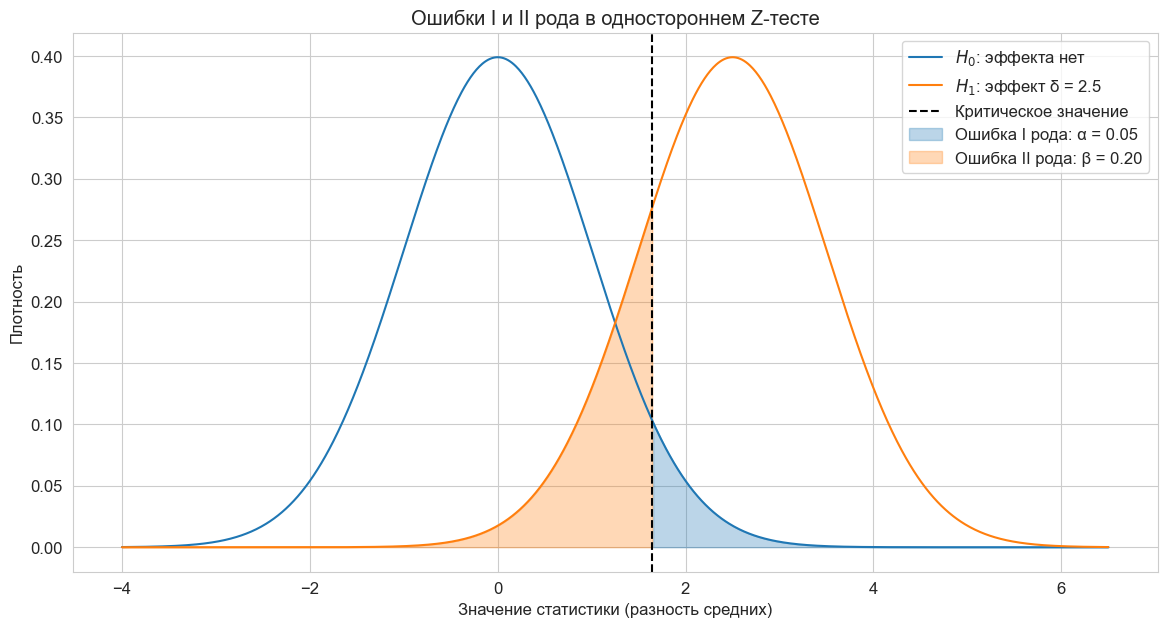

In [5]:
plot_error_distributions(delta=2.5, se=1.0, alpha=0.05)

### MDE

**MDE (Minimum Detectable Effect)** — наименьший эффект, который тест различает с вероятностью 80% (мощность $1 - \beta$ при заданном α). Для разности средних в двух группах по $n$ наблюдений:

$$
\text{MDE} = \left(z_{1-\alpha} + z_{1-\beta}\right)\sigma\sqrt{\frac{2}{n}}.
$$

MDE убывает как $1/\sqrt{n}$: чтобы уменьшить его вдвое, выборку нужно увеличить вчетверо; второй рычаг — снизить дисперсию метрики (часть 3).


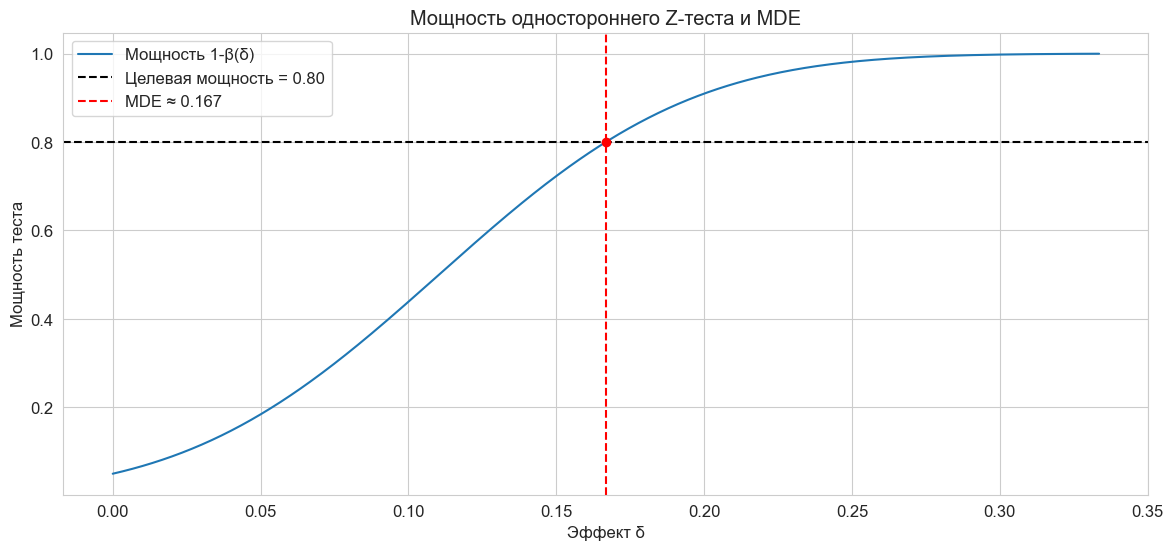

При n=1000 в группе, σ=1.50, α=0.05 и мощности 0.80 MDE ≈ 0.167


0.16679780437430508

In [7]:
calculate_and_plot_mde(n = 1000,
                       sigma = 1.5,
                       alpha = 0.05,
                       target_power = 0.8)

## Виды тестов

Тесты различают по цели (что доказываем), по направленности (в какую сторону смотрим) и по критерию (чем считаем).


### Цель тестирования

По цели выделяют три вида тестов (μ — разность «новое − старое», δ — порог, значимый для бизнеса):

| Вид | $H_0$ | $H_1$ | Что доказываем |
|---|---|---|---|
| Superiority (превосходство) | $\mu \le \delta$ | $\mu > \delta$ | новое строго лучше минимум на δ |
| Non-inferiority (не хуже) | $\mu \le -\delta$ | $\mu > -\delta$ | новое хуже не более чем на δ |
| Equivalence (эквивалентность) | $|\mu| \ge \delta$ | $|\mu| < \delta$ | разность внутри ±δ (TOST: два односторонних) |


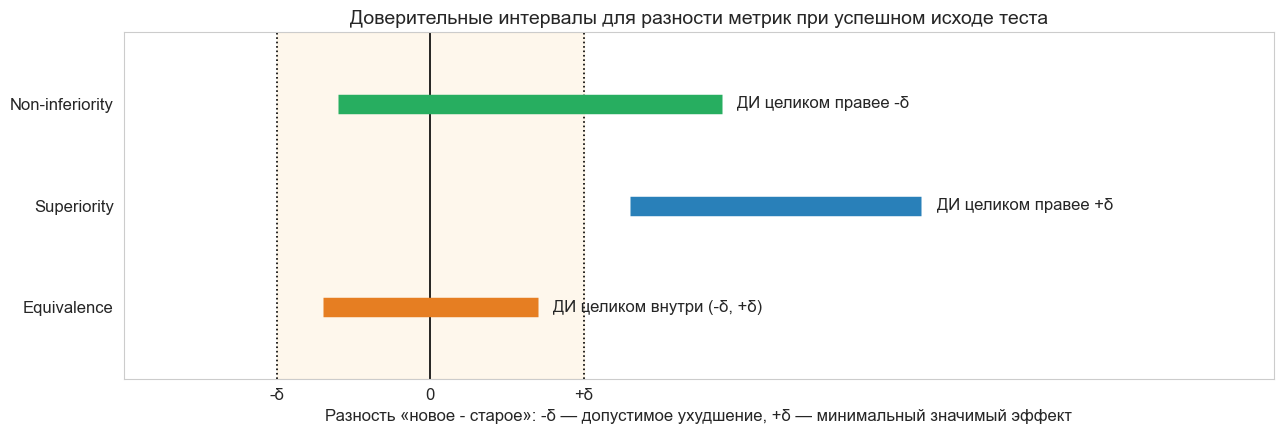

In [2]:
# Примеры доверительных интервалов для разности «новое - старое» при успешном исходе теста
margin = 1.0
examples = [
    ('Equivalence', (-0.7, 0.7), '#e67e22', 'ДИ целиком внутри (-δ, +δ)'),
    ('Superiority', (1.3, 3.2), '#2980b9', 'ДИ целиком правее +δ'),
    ('Non-inferiority', (-0.6, 1.9), '#27ae60', 'ДИ целиком правее -δ'),
]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.axvspan(-margin, margin, color='#f39c12', alpha=0.08)
for x in (-margin, 0, margin):
    ax.axvline(x, color='black', linestyle=':' if x else '-', linewidth=1.2)
for row, (name, (left, right), color, note) in enumerate(examples):
    ax.plot([left, right], [row, row], color=color, linewidth=14, solid_capstyle='butt')
    ax.text(right + 0.1, row, note, va='center', fontsize=12)
ax.set_yticks(range(3), labels=[e[0] for e in examples])
ax.set_xticks([-margin, 0, margin], labels=['-δ', '0', '+δ'])
ax.set_xlabel('Разность «новое - старое»: -δ — допустимое ухудшение, +δ — минимальный значимый эффект')
ax.set_xlim(-2, 5.5)
ax.set_ylim(-0.7, 2.7)
ax.grid(False)
ax.set_title('Доверительные интервалы для разности метрик при успешном исходе теста', fontsize=14)
plt.tight_layout()
plt.show()

### Направленность альтернативной гипотезы

Односторонний тест проверяет эффект в одну сторону (только рост или только падение), двусторонний — в любую. Направление фиксируют **до** старта: выбирать его по данным нельзя — фактический α удвоится. Guardrail-метрики обычно проверяют односторонне.


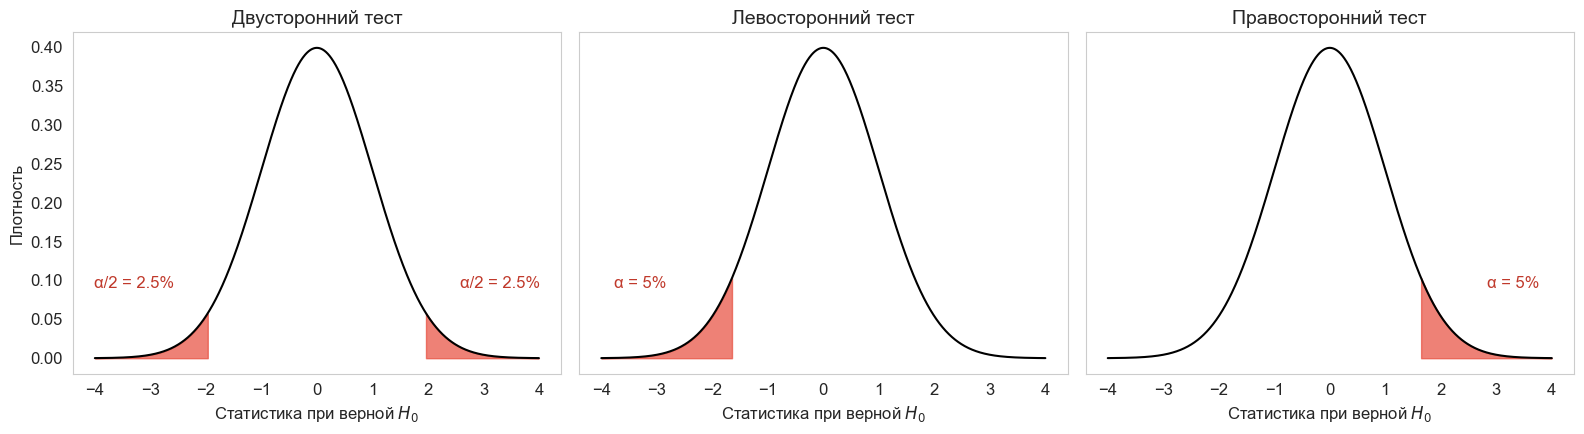

In [3]:
alpha = 0.05
x = np.linspace(-4, 4, 1_000)
pdf = stats.norm.pdf(x)
z_two, z_one = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(1 - alpha)

zones = [
    ('Двусторонний тест', [(x <= -z_two, 'α/2 = 2.5%', -3.3), (x >= z_two, 'α/2 = 2.5%', 3.3)]),
    ('Левосторонний тест', [(x <= -z_one, 'α = 5%', -3.3)]),
    ('Правосторонний тест', [(x >= z_one, 'α = 5%', 3.3)]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (title, areas) in zip(axes, zones):
    ax.plot(x, pdf, color='black')
    for mask, label, x_text in areas:
        ax.fill_between(x[mask], pdf[mask], color='#e74c3c', alpha=0.7)
        ax.text(x_text, 0.09, label, ha='center', fontsize=12, color='#c0392b')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Статистика при верной $H_0$')
    ax.grid(False)
axes[0].set_ylabel('Плотность')
plt.tight_layout()
plt.show()

### Статистические критерии

Статистически значимая разница — та, которую трудно объяснить случайностью; p-value — вероятность получить такую или более экстремальную разницу при верной $H_0$ (это **не** вероятность, что $H_0$ верна). Критерий выбирают под тип метрики:

| Вид теста | Критерий | Данные | Предпосылки | Когда используем |
|---|---|---|---|---|
| Параметрический | z-тест | непрерывная (средние, доли при больших n) | известна σ или n > 30; независимость; ЦПТ | средний чек, конверсия на больших выборках |
| Параметрический | t-тест / Welch | непрерывная (средние) | нормальность или ЦПТ; независимость; Welch — без равенства дисперсий | малые выборки, неизвестна σ |
| Непараметрический | χ²-тест | категориальная (таблица сопряжённости) | независимость; ожидаемые частоты ≥ 5 | конверсия (2×2), распределение по категориям |
| Непараметрический | Mann–Whitney U | ранги (стохастический порядок) | независимость; не проверяет средние/медианы | порядковые метрики, скошенные данные |

Бутстреп — универсальная замена, когда предпосылки не выполняются.

Готовые вызовы:


In [ ]:
def two_sample_z_test(control, test):
    """Z-тест для двух независимых выборок (σ известна или n велико)."""
    n1, n2 = len(control), len(test)
    se = np.sqrt(np.var(control, ddof=1) / n1 + np.var(test, ddof=1) / n2)
    z = (np.mean(test) - np.mean(control)) / se
    return z, 2 * stats.norm.sf(abs(z))


def welch_t_test(control, test):
    """t-тест Уэлча: без предположения о равенстве дисперсий."""
    res = stats.ttest_ind(control, test, equal_var=False)
    return float(res.statistic), float(res.pvalue)


def chi2_independence(observed):
    """χ²-тест независимости: строки — категории, столбцы — группы."""
    chi2, p, dof, _ = stats.chi2_contingency(observed)
    return float(chi2), float(p), int(dof)


def mann_whitney_test(control, test):
    """U-тест Манна–Уитни: сравнивает стохастический порядок, а не средние/медианы."""
    u, p = stats.mannwhitneyu(control, test, alternative='two-sided')
    return float(u), float(p)


## Часть 2. Что мерить: метрики

План есть — теперь решаем, какие метрики играют какие роли, в каком порядке читать результат и как не обмануться при интерпретации.

## Виды метрик и как их тестируем

Сначала роли метрик и порядок чтения результата, затем — как каждую роль тестируем с точки зрения поправок.


### Сквозной кейс и роли метрик

Все примеры занятия живут в одном продукте: приложении доставки еды. Главная цель бизнеса — чтобы пользователи заказывали больше и дольше оставались. Мы формулируем её как **долгосрочную метрику (north star)**: число заказов на пользователя за 28 дней. Проблема в том, что узнать её можно только через четыре недели, а тест нужно закончить раньше. Поэтому в тесте мы смотрим не на одну метрику, а на несколько, и у каждой своя роль.

Роли удобно разделять по тому, **что мы с метрикой делаем**. Эта классификация из статьи Microsoft ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)) дополняет разбиение success/guardrail/deterioration/quality из [занятия 1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB): она отвечает на вопрос «в каком порядке читать результат», а не «как считать поправки».

* **Метрики качества данных.** Первый вопрос: можно ли вообще доверять эксперименту. Главная из них — доля пользователей в группах, то есть [SRM](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5). Сюда же относятся доли потерянной телеметрии и сверка клиентских событий с серверными.
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Она измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально, когда она одна. В нашем кейсе это заказы за первые 7 дней.
* **Guardrail-метрики.** Метрики, которые не должны заметно ухудшиться, даже если OEC растёт: отписки от пушей, время доставки, доля возвратов.
* **Локальные и диагностические метрики.** Клики по конкретной кнопке, шаги воронки, CTR отдельного блока. Они объясняют, откуда взялось движение OEC, но сами решения не принимают.

Порядок чтения результата следует из ролей: сначала убеждаемся, что данным можно верить, потом смотрим OEC, потом проверяем, что ничего не сломали, и только потом разбираемся, почему так вышло.

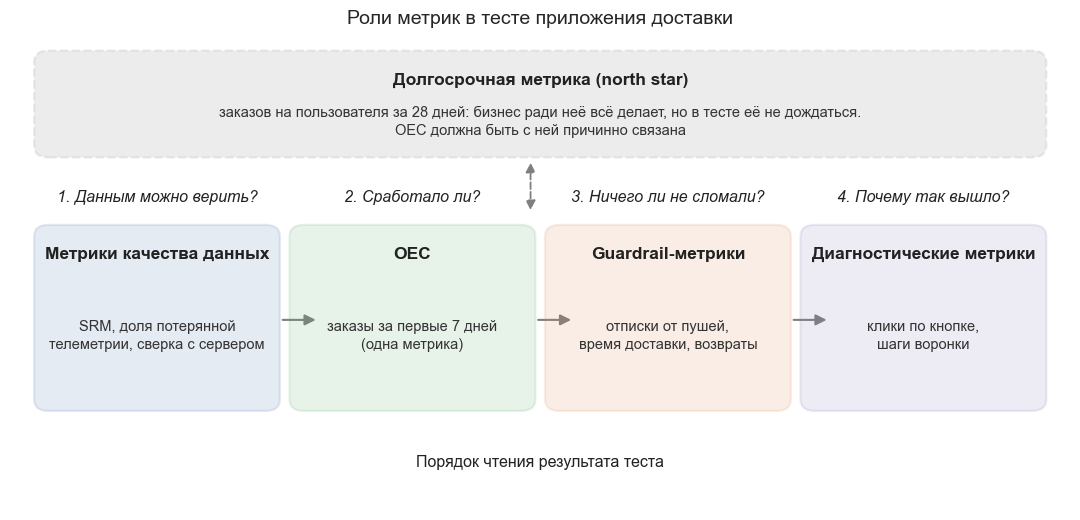

In [2]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')
    ax.grid(False)

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color, edgecolor=GRAY if dashed else color,
                                    alpha=.14, linewidth=1.6, linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)', 'заказов на пользователя за 28 дней: бизнес ради неё всё делает, но в тесте её не дождаться.\nOEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Метрики качества данных', 'SRM, доля потерянной\nтелеметрии, сверка с сервером', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'заказы за первые 7 дней\n(одна метрика)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail-метрики', 'отписки от пушей,\nвремя доставки, возвраты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические метрики', 'клики по кнопке,\nшаги воронки', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте приложения доставки', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

### Разные метрики тестируются по-разному

Поправка на множественность следует из правила запуска, а не навешивается на все метрики одинаково (фреймворк Spotify, [arXiv:2402.11609](https://arxiv.org/abs/2402.11609); подробно — в занятии о множественном тестировании).

* **Основная метрика (OEC / success)** — одна, поэтому тестируем без поправки.
* **Вторичные (диагностические)** — читаем как заранее определённое «семейство»: если их много, «хотя бы одна» почти наверняка выстрелит случайно, поэтому применяем поправку (например Холма) по семейству.
* **Guardrail** — односторонний non-inferiority без поправки на α: условие «все должны пройти» не накапливает α, но снижает мощность, поэтому поправляют β — каждый тест считают на мощность $1 - \frac{\beta}{G+1}$.

| Роль | Что проверяем | Правило запуска | Уровень значимости |
|---|---|---|---|
| Основная (OEC / success) | superiority | одна метрика | α, без поправки |
| Вторичные (диагностические) | superiority | «хотя бы одна» как объяснение | α с поправкой по семейству |
| Guardrail | non-inferiority | «все значимо не хуже» | односторонний, α без поправки |


## Ловушки интерпретации

Дальше — ловушки, из-за которых честно посчитанный тест можно прочитать неверно: от оптимизации одной метрики через усреднение и сегменты к проблемам самих данных. В конце — чек-лист.


### Закон Гудхарта: что бывает, если оптимизировать одну метрику

Метрика полезна, пока она индикатор; как только её превращают в цель, её начинают двигать любыми способами, в том числе вредными (закон Гудхарта).

Команда пушей получила цель «вырастить число сессий на пользователя» и тестирует 200 идей. Часть идей честные (растут и сессии, и заказы), часть — накрутка: навязчивые пуши дают сессии, но роняют заказы. Долю накрутки закладываем 30% — это допущение модели, а не факт о реальных командах.

Сравним две политики запуска:

* **A.** Запускаем всё, где сессии значимо выросли.
* **B.** То же, но с guardrail: нижняя граница 95% ДИ по заказам должна быть выше −2%.


In [3]:
def goodhart_round(rng, n=200, gaming=.3, se_sessions=.6, se_orders=.6, margin=-2.0):
    """Одна «жизнь» команды: n идей, истинные эффекты в % на сессии и заказы, измеренные с шумом."""
    is_gaming = rng.random(n) < gaming
    sessions = np.where(is_gaming, rng.normal(2.0, 1.0, n), rng.normal(.5, 1.0, n))
    orders = np.where(is_gaming, rng.normal(-1.2, .6, n), .6 * sessions + rng.normal(0, .5, n))
    s_hat = sessions + rng.normal(0, se_sessions, n)
    o_hat = orders + rng.normal(0, se_orders, n)
    ship_a = s_hat / se_sessions > 1.96
    ship_b = ship_a & (o_hat - 1.96 * se_orders > margin)
    return {'policy': ['A: только сессии', 'B: сессии + guardrail'],
            'shipped': [ship_a.sum(), ship_b.sum()],
            'gaming_shipped': [(ship_a & is_gaming).sum(), (ship_b & is_gaming).sum()],
            'sessions': [sessions[ship_a].sum(), sessions[ship_b].sum()],
            'orders': [orders[ship_a].sum(), orders[ship_b].sum()]}


rounds = [goodhart_round(np.random.default_rng(seed)) for seed in range(500)]
gh = pd.DataFrame([{'policy': r['policy'][k], **{key: r[key][k] for key in ('shipped', 'gaming_shipped', 'sessions', 'orders')}} for r in rounds for k in (0, 1)])
summary = gh.groupby('policy').agg(shipped=('shipped', 'mean'), gaming_shipped=('gaming_shipped', 'mean'),
                                   sessions=('sessions', 'mean'), orders_mean=('orders', 'mean'), orders_p10=('orders', lambda x: x.quantile(.1)),
                                   orders_p90=('orders', lambda x: x.quantile(.9)))
summary.columns = ['запущено идей', 'из них накрутка', 'Σ эффект на сессии, %', 'Σ эффект на заказы, % (среднее)', 'то же, 10-й перцентиль', 'то же, 90-й перцентиль']
print(summary.round(1).to_string())

                       запущено идей  из них накрутка  Σ эффект на сессии, %  Σ эффект на заказы, % (среднее)  то же, 10-й перцентиль  то же, 90-й перцентиль
policy                                                                                                                                                       
A: только сессии                84.9             45.4                  167.2                            -18.6                   -33.2                    -5.1
B: сессии + guardrail           53.4             14.9                   94.4                             25.2                    16.0                    33.9


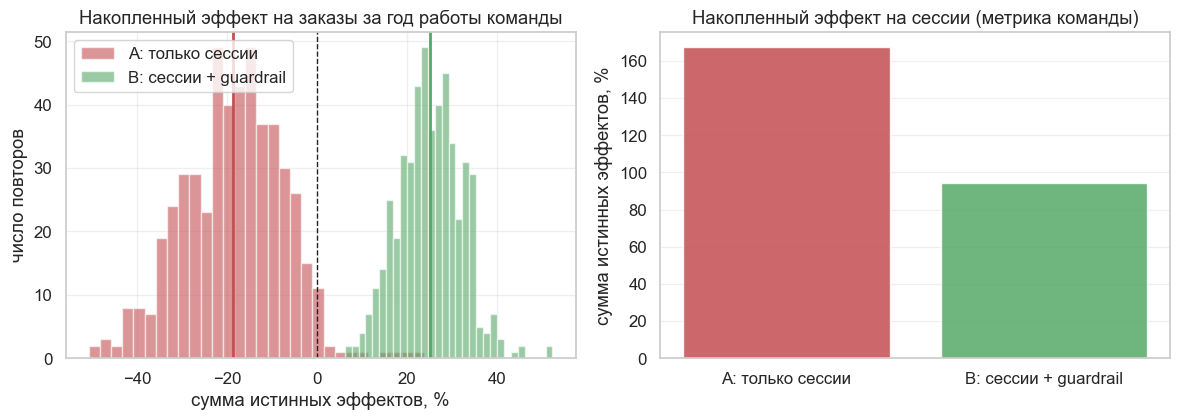

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
colors = {'A: только сессии': RED, 'B: сессии + guardrail': GREEN}
for name, color in colors.items():
    part = gh[gh.policy == name]
    axes[0].hist(part.orders, bins=30, color=color, alpha=.6, label=name)
    axes[0].axvline(part.orders.mean(), color=color, linewidth=2)
    axes[1].bar(name, part.sessions.mean(), color=color, alpha=.85)
axes[0].axvline(0, color='#222222', linewidth=1, linestyle='--')
axes[0].set_title('Накопленный эффект на заказы за год работы команды')
axes[0].set_xlabel('сумма истинных эффектов, %')
axes[0].set_ylabel('число повторов')
axes[0].legend(loc='upper left')
axes[1].set_title('Накопленный эффект на сессии (метрика команды)')
axes[1].set_ylabel('сумма истинных эффектов, %')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Политика A выигрывает по метрике, на которой её оценивают: по сессиям ≈ +167 п.п. против +94 у политики B. Но плата — накрутки: A запускает в среднем 45 накруток из 85 идей, и **заказы в сумме уходят в минус** (≈ −19 п.п. в среднем). Политика B запускает 15 накруток и 38 честных идей и даёт ≈ +25 п.п. по заказам. Guardrail отсекает почти всю накрутку, но и сессий добавляется меньше — это цена защиты, и платить её надо осознанно.

Правило: **у метрики-цели всегда должна быть пара guardrail-метрик, определённых до запуска**, в идеале — контрметрика, которая ломается ровно тогда, когда метрику накручивают (например, доля сессий с заказом).


#### Проверьте себя

**Ситуация 1.** Команда оптимизирует «среднее время в приложении». Тест нового экрана показал +9% к времени в приложении, а число заказов на пользователя не изменилось (p = 0.4). Запускаем?

<details>
<summary>Ответ</summary>

Нельзя просто радоваться росту времени. Время может расти из-за того, что пользователю труднее найти нужное: он дольше листает и ищет. Нужны контрметрики: доля сессий с заказом, время до первого заказа, доля поисков без результата. Отсутствие эффекта на заказах при росте времени как раз намекает на ухудшение, а не на выигрыш. Рост времени сам по себе нельзя считать победой, пока не проверено, что он идёт вместе с ростом долгосрочной ценности.
</details>

### Парадокс Симпсона: меняющиеся доли

Тест часто запускают постепенно: сначала на малой доле трафика, потом шире, чтобы ограничить ущерб от возможного бага. Но если доля теста меняется во времени, а поведение пользователей тоже меняется во времени (будни и выходные, акции, сезон), общий итог по периоду может показать **обратный** знак по сравнению с каждым днём. Это парадокс Симпсона. Crook, Frasca, Kohavi и Longbotham ([KDD 2009](https://exp-platform.com/seven-pitfalls/)) называют его среди ловушек, которые они встречали при запуске экспериментов в вебе: при постепенном росте доли теста легко выбрать неправильного победителя.

Наш случай. Неделя теста: в будни тест получает 50% трафика, а в выходные его, из осторожности перед пиком, снижают до 10%. В выходные конверсия выше. Тест на самом деле **повышает** конверсию на 1 п.п. в любой день.

In [20]:
def simulate_ramp(rng, daily=30000, effect=.01):
    """Неделя теста: конверсия и доля теста зависят от дня; истинный эффект теста +1 п.п. каждый день."""
    days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    base = [.08] * 5 + [.14] * 2
    share = [.5] * 5 + [.1] * 2
    rows = []
    for day, b, s in zip(days, base, share):
        n_test = rng.binomial(daily, s)
        n_ctrl = daily - n_test
        rows.append({'день': day, 'доля теста': s, 'n_контроль': n_ctrl, 'n_тест': n_test,
                     'конверсия_контроль': rng.binomial(n_ctrl, b) / n_ctrl, 'конверсия_тест': rng.binomial(n_test, b + effect) / n_test})
    return pd.DataFrame(rows)


ramp = simulate_ramp(np.random.default_rng(0))
conv_ctrl = (ramp['конверсия_контроль'] * ramp['n_контроль']).sum() / ramp['n_контроль'].sum()
conv_test = (ramp['конверсия_тест'] * ramp['n_тест']).sum() / ramp['n_тест'].sum()
daily_delta = ramp['конверсия_тест'] - ramp['конверсия_контроль']
daily_var = ramp['конверсия_контроль'] * (1 - ramp['конверсия_контроль']) / ramp['n_контроль'] + ramp['конверсия_тест'] * (1 - ramp['конверсия_тест']) / ramp['n_тест']
weights = 1 / daily_var
stratified = (weights * daily_delta).sum() / weights.sum()
stratified_se = np.sqrt(1 / weights.sum())
pooled_delta = conv_test - conv_ctrl
pooled_se = np.sqrt(conv_ctrl * (1 - conv_ctrl) / ramp['n_контроль'].sum() + conv_test * (1 - conv_test) / ramp['n_тест'].sum())
print(ramp.assign(**{'разница, п.п.': (100 * daily_delta).round(2)}).round(4).to_string(index=False))
print(f'\nОбщий итог за неделю: контроль {100 * conv_ctrl:.2f}%, тест {100 * conv_test:.2f}%, разница {100 * pooled_delta:+.2f} п.п. (SE {100 * pooled_se:.2f})')
print(f'С учётом дня (дни взвешены по точности): {100 * stratified:+.2f} п.п. (SE {100 * stratified_se:.2f}), истина +1.00')

день  доля теста  n_контроль  n_тест  конверсия_контроль  конверсия_тест  разница, п.п.
  Пн         0.5       14892   15108              0.0802          0.0904           1.02
  Вт         0.5       15040   14960              0.0791          0.0907           1.17
  Ср         0.5       14851   15149              0.0810          0.0899           0.89
  Чт         0.5       15016   14984              0.0812          0.0922           1.09
  Пт         0.5       14951   15049              0.0825          0.0874           0.48
  Сб         0.1       26957    3043              0.1389          0.1623           2.34
  Вс         0.1       26951    3049              0.1421          0.1456           0.35

Общий итог за неделю: контроль 10.58%, тест 9.49%, разница -1.09 п.п. (SE 0.13)
С учётом дня (дни взвешены по точности): +0.96 п.п. (SE 0.14), истина +1.00


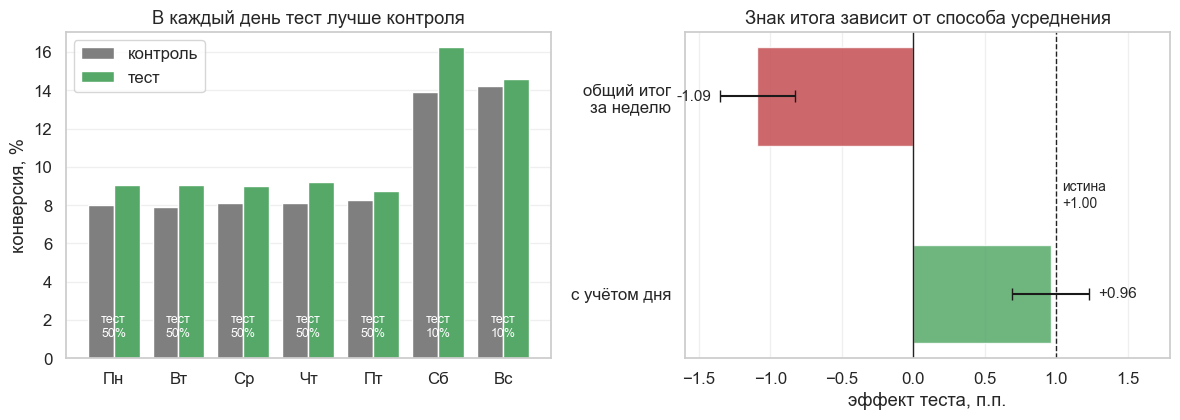

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(7)
axes[0].bar(x - .2, 100 * ramp['конверсия_контроль'], width=.4, color=GRAY, label='контроль')
axes[0].bar(x + .2, 100 * ramp['конверсия_тест'], width=.4, color=GREEN, label='тест')
for k, s in enumerate(ramp['доля теста']):
    axes[0].text(k, 1, f'тест\n{100 * s:.0f}%', ha='center', va='bottom', fontsize=9, color='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(ramp['день'])
axes[0].set_ylabel('конверсия, %')
axes[0].set_title('В каждый день тест лучше контроля')
axes[0].legend(loc='upper left')
axes[0].grid(axis='x', visible=False)
estimates = [('общий итог\nза неделю', pooled_delta, pooled_se, RED), ('с учётом дня', stratified, stratified_se, GREEN)]
for k, (name, value, se, color) in enumerate(estimates):
    axes[1].barh(k, 100 * value, xerr=196 * se, color=color, alpha=.85, height=.5, capsize=4)
    axes[1].text(100 * value + np.sign(value) * (196 * se + .06), k, f'{100 * value:+.2f}', va='center', ha='left' if value > 0 else 'right', fontsize=11)
axes[1].axvline(1.0, color='#222222', linestyle='--', linewidth=1)
axes[1].text(1.04, .5, 'истина\n+1.00', fontsize=10, va='center')
axes[1].set_xlim(-1.6, 1.8)
axes[1].axvline(0, color='#222222', linewidth=1)
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels([e[0] for e in estimates])
axes[1].invert_yaxis()
axes[1].set_xlabel('эффект теста, п.п.')
axes[1].set_title('Знак итога зависит от способа усреднения')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Тест стал выглядеть вредным (общий итог −1.09 п.п. при стандартной ошибке 0.13): в нём слишком много будней, когда конверсия низкая, и слишком мало выходных, когда она высокая. С учётом дня оценка +0.96 п.п. при истинных +1.00. Разница между группами в итоге складывается из эффекта теста **и разной структуры дней**. В каждый отдельный день тест лучше контроля.

Как с этим жить:

* **Не менять долю теста по ходу, если можно.** Лучше подбирать фиксированную долю и держать её весь тест.
* **Если долю всё же меняют, анализировать с учётом периода:** считать эффект внутри каждого периода с постоянной долей и объединять (например, взвешивая по точности, как выше, или регрессией с фиксированными эффектами дня). Тогда структура дней уходит из сравнения.
* **Проверять SRM по периодам.** Если доля менялась, суммарная доля групп за весь тест не равна плановой, и обычная проверка SRM по тесту целиком даст ложную тревогу. Её нужно делать внутри каждого периода с постоянной долей.

### Сегменты: скрытая множественность и сегмент, зависящий от воздействия

Результат хочется разрезать: по платформе, городу, давности пользователя. Разрезы полезны для отладки и поиска неоднородности эффекта, но у них три ловушки.

**Первая: множественность.** Если смотреть 20 сегментов, значимый хотя бы в одном найдётся с вероятностью около 64% даже при нулевом эффекте. Покажем на A/A-тесте с 20 сегментами по 4000 пользователей в группе.

In [22]:
def aa_segments(rng, reps=1000, segments=20, n=4000, p=.10):
    """A/A: доля тестов, где хотя бы один сегмент значим без поправки и после поправки Холма."""
    any_raw, any_holm = 0, 0
    for _ in range(reps):
        a, b = rng.binomial(n, p, segments), rng.binomial(n, p, segments)
        pooled = (a + b) / (2 * n)
        z = (b - a) / n / np.sqrt(2 * pooled * (1 - pooled) / n)
        pvalues = 2 * st.norm.sf(np.abs(z))
        any_raw += (pvalues < .05).any()
        ordered = np.sort(pvalues)
        any_holm += ordered[0] <= .05 / segments  # Холм отвергает хоть одну гипотезу, только если min p ≤ α/m
    return any_raw / reps, any_holm / reps


aa_raw, aa_holm = aa_segments(np.random.default_rng(1))
print(f'Хотя бы один значимый из 20 сегментов в A/A: без поправки {100 * aa_raw:.0f}%, с поправкой Холма {100 * aa_holm:.1f}%')

Хотя бы один значимый из 20 сегментов в A/A: без поправки 65%, с поправкой Холма 5.5%


Без поправки «находка» есть в двух тестах из трёх, с поправкой ложных срабатываний около 5%. Сегменты, которые мы будем смотреть, нужно **заранее перечислить** и считать единым семейством гипотез (см. [занятие 1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7)).

**Вторая ловушка: «значимо здесь, не значимо там» ничего не говорит о разнице эффектов.** Допустим, у iOS 40 тысяч пользователей в группе, у Android 10 тысяч, а истинный эффект везде одинаков: +0.8 п.п. к конверсии 10%. Мощности у сегментов разные, поэтому часто значим только iOS. Но вывод «на Android не работает» неверен. Правильно проверять **взаимодействие**: значимо ли отличаются эффекты в сегментах.

In [23]:
def significant_here_not_there(rng, reps=3000, p=.10, effect=.008, sizes=(40000, 10000)):
    """Эффект одинаков в двух сегментах. Как часто значим только в первом и как часто значимо взаимодействие."""
    only_first, interaction, only_first_and_interaction = 0, 0, 0
    for _ in range(reps):
        deltas, ses = [], []
        for n in sizes:
            a, b = rng.binomial(n, p), rng.binomial(n, p + effect)
            deltas.append((b - a) / n)
            ses.append(np.sqrt(2 * p * (1 - p) / n))
        significant = [abs(d / s) > 1.96 for d, s in zip(deltas, ses)]
        inter = abs((deltas[0] - deltas[1]) / np.hypot(*ses)) > 1.96
        interaction += inter
        if significant[0] and not significant[1]:
            only_first += 1
            only_first_and_interaction += inter
    return only_first / reps, interaction / reps, only_first_and_interaction / max(only_first, 1)


only_first, inter_all, inter_in_only_first = significant_here_not_there(np.random.default_rng(2))
print(f'Значим только iOS (не значим Android): {100 * only_first:.0f}% тестов')
print(f'Взаимодействие значимо: {100 * inter_all:.1f}% тестов при истинном отсутствии взаимодействия')
print(f'Среди тестов «только iOS» взаимодействие значимо в {100 * inter_in_only_first:.1f}%')

Значим только iOS (не значим Android): 48% тестов
Взаимодействие значимо: 5.1% тестов при истинном отсутствии взаимодействия
Среди тестов «только iOS» взаимодействие значимо в 4.7%


Половина тестов даёт картину «работает на iOS, на Android не работает», хотя эффекты равны. Проверка на взаимодействие почти никогда не подтверждает разницу, и это правильно: данных для такого вывода просто нет. В задаче «катим только на Android» нужно смотреть на разницу эффектов и её доверительный интервал.

**Третья ловушка: сегмент определён по признаку, на который влияет воздействие.** В примере из статьи Microsoft: в Bing разрезали пользователей на тех, кто увидел «глубокие ссылки» в выдаче, и тех, кто не увидел. В обоих сегментах число сессий на пользователя значимо выросло, а в целом по тесту осталось прежним. Эксперимент на сессии не влиял, но он изменил, кто попадает в сегмент: менее активные пользователи выпали из первого сегмента во второй, и в обоих средняя активность выросла.

Воспроизведём механизм. В нашем кейсе сегмент «видит блок рекомендаций» зависит от активности, а тест сместил порог: умеренно активные пользователи перестали его видеть. Сессии никак не менялись.

In [24]:
def post_treatment_segments(rng, n=60000):
    """Сессии не меняются, но тест меняет состав сегмента «видит блок»: умеренно активные пользователи в тесте его не видят."""
    activity = rng.gamma(2.0, 1.0, 2 * n)
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    sees = np.where(arm, activity > 3.0, activity > 2.2)
    sessions = rng.poisson(activity).astype(float)
    rows = []
    for name, mask in (('видят блок', sees), ('не видят блок', ~sees), ('все пользователи', np.ones(2 * n, bool))):
        a, b = sessions[~arm & mask], sessions[arm & mask]
        effect, se = rel_effect(a, b)
        rows.append({'сегмент': name, 'эффект на сессии': effect, 'SE': se, 'доля в контроле': mask[~arm].mean(), 'доля в тесте': mask[arm].mean()})
    share_p = st.chi2_contingency([[sees[~arm].sum(), (~sees[~arm]).sum()], [sees[arm].sum(), (~sees[arm]).sum()]])[1]
    return pd.DataFrame(rows).set_index('сегмент'), share_p


segments, share_p = post_treatment_segments(np.random.default_rng(3))
print(segments.assign(**{'эффект на сессии': segments['эффект на сессии'].map(pct), 'SE': (100 * segments['SE']).round(1),
                         'доля в контроле': (100 * segments['доля в контроле']).round(1), 'доля в тесте': (100 * segments['доля в тесте']).round(1)}).to_string())
print(f'\nПроверка равенства долей сегмента «видят блок» в группах: p {"< 1e-300" if share_p < 1e-300 else "= " + format(share_p, ".1e")}')

                 эффект на сессии   SE  доля в контроле  доля в тесте
сегмент                                                              
видят блок                 +20.6%  0.8             35.6          20.0
не видят блок              +21.7%  0.8             64.4          80.0
все пользователи            -0.9%  0.6            100.0         100.0

Проверка равенства долей сегмента «видят блок» в группах: p < 1e-300


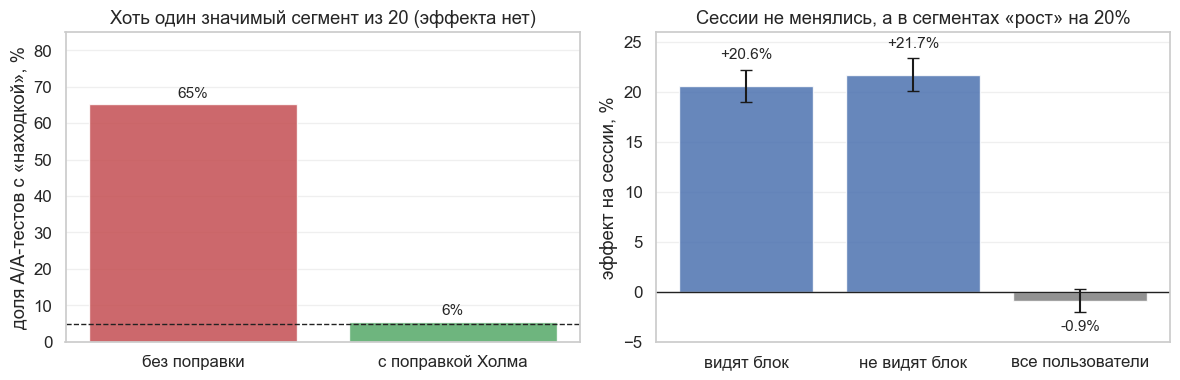

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['без поправки', 'с поправкой Холма'], [100 * aa_raw, 100 * aa_holm], color=[RED, GREEN], alpha=.85)
for k, v in enumerate([100 * aa_raw, 100 * aa_holm]):
    axes[0].text(k, v + 2, f'{v:.0f}%', ha='center', fontsize=11)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].set_ylim(0, 85)
axes[0].set_ylabel('доля A/A-тестов с «находкой», %')
axes[0].set_title('Хоть один значимый сегмент из 20 (эффекта нет)')
axes[0].grid(axis='x', visible=False)
order = segments.index
values = 100 * segments['эффект на сессии']
axes[1].bar(order, values, yerr=196 * segments['SE'], color=[BLUE, BLUE, GRAY], alpha=.85, capsize=4)
for k, (v, se) in enumerate(zip(values, 196 * segments['SE'])):
    axes[1].text(k, v + se + .8 if v >= 0 else v - se - .8, f'{v:+.1f}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=11)
axes[1].set_ylim(-5, 26)
axes[1].axhline(0, color='#222222', linewidth=1)
axes[1].set_ylabel('эффект на сессии, %')
axes[1].set_title('Сессии не менялись, а в сегментах «рост» на 20%')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Оба сегмента показывают рост около 20%, а общий эффект равен нулю: изменился состав сегментов. Лекарство то же, что для SRM, только на уровне сегмента: **проверять, что доля пользователей в сегменте одинакова в группах** (здесь p ≈ 0, доля упала с 36% до 20%). Если не одинакова, сегмент определён по признаку, на который воздействие повлияло, и его нельзя использовать для сравнения. Безопасны сегменты по признакам, зафиксированным до назначения (платформа, страна, давность регистрации).

#### Проверьте себя

**Ситуация 5.** После теста аналитик сообщает: «на Android эффект значим (p = 0.03), на iOS нет (p = 0.30), запускаем только на Android». Что вы проверите до решения?

<details>
<summary>Ответ</summary>

Первое: значимо ли различие эффектов между платформами. Значим в одном и не значим в другом — не доказательство различия: сегменты могут отличаться только размером и, соответственно, мощностью. Второе: был ли сегмент одним из заранее выбранных или аналитик нашёл его среди многих разрезов (множественность). Третье: одинакова ли доля платформ в группах. Если различия эффектов нет, а платформа запланирована заранее, разумнее запускать на всех и смотреть на объединённый эффект.
</details>

### Неполные воронки

Многие пути пользователя устроены как воронка: открыл корзину, нажал «Оплатить», оплата прошла. Лёгкий способ улучшить метрику на одном шаге — сместить внимание пользователя на него. В Microsoft в экспериментах на Xbox с промо-акциями небольшие изменения картинок и текстов сильно повышали клики по распродаже, но выручка не росла, при том что мощности хватало ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)). Пользователи просто тратили лишнее время.

Поэтому в воронке нужно считать **оба вида метрик по всем шагам**: условные (доля прошедших шаг среди дошедших до него) и безусловные (доля прошедших шаг среди всех, кто начал воронку).

Новая кнопка оплаты в нашем кейсе: она заметнее, на неё нажимают чаще, но платёж проходит реже, потому что часть пользователей жмёт случайно и сдаётся на странице банка.

In [26]:
def simulate_funnel(rng, n=50000):
    """Воронка корзина → клик «Оплатить» → успешная оплата. В тесте клик чаще, а оплата среди кликнувших реже."""
    rows = {}
    for arm, click_rate, success_rate in (('контроль', .50, .85), ('тест', .60, .70)):
        click = rng.random(n) < click_rate
        success = click & (rng.random(n) < success_rate)
        rows[arm] = dict(click=click.astype(float), success=success.astype(float))
    return rows


funnel = simulate_funnel(np.random.default_rng(6))
c, t = funnel['контроль'], funnel['тест']
click_eff = rel_effect(c['click'], t['click'])
cond_eff = rel_effect(c['success'][c['click'] > 0], t['success'][t['click'] > 0])
uncond_eff = rel_effect(c['success'], t['success'])
steps = pd.DataFrame({'шаг': ['клик «Оплатить» (безусловно)', 'оплата среди кликнувших (условно)', 'оплата среди всех (безусловно)'],
                      'контроль': [c['click'].mean(), c['success'][c['click'] > 0].mean(), c['success'].mean()],
                      'тест': [t['click'].mean(), t['success'][t['click'] > 0].mean(), t['success'].mean()],
                      'эффект': [click_eff[0], cond_eff[0], uncond_eff[0]], 'SE': [click_eff[1], cond_eff[1], uncond_eff[1]]})
print(steps.assign(контроль=(100 * steps['контроль']).round(1), тест=(100 * steps['тест']).round(1), эффект=steps['эффект'].map(pct), SE=(100 * steps['SE']).round(1)).to_string(index=False))

                              шаг  контроль  тест эффект  SE
     клик «Оплатить» (безусловно)      50.3  60.5 +20.4% 0.7
оплата среди кликнувших (условно)      84.7  69.5 -18.0% 0.4
   оплата среди всех (безусловно)      42.6  42.0  -1.2% 0.7


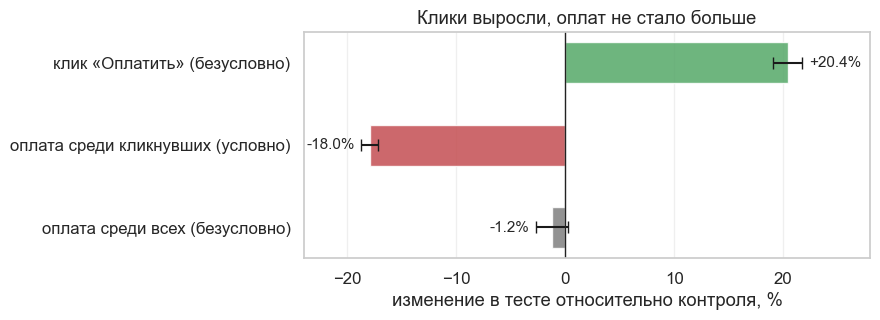

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [GREEN, RED, GRAY]
for k, (row, color) in enumerate(zip(steps.itertuples(), colors)):
    ax.barh(k, 100 * row.эффект, xerr=196 * row.SE, color=color, alpha=.85, height=.5, capsize=4)
    ax.text(100 * row.эффект + np.sign(row.эффект) * (196 * row.SE + .6), k, pct(row.эффект), va='center', ha='left' if row.эффект > 0 else 'right', fontsize=11)
ax.axvline(0, color='#222222', linewidth=1)
ax.set_yticks(range(3))
ax.set_yticklabels(steps['шаг'])
ax.invert_yaxis()
ax.set_xlim(-24, 28)
ax.set_xlabel('изменение в тесте относительно контроля, %')
ax.set_title('Клики выросли, оплат не стало больше')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Если смотреть только на клик, тест выигрывает на 20%. Условная метрика показывает причину: среди кликнувших платёж проходит реже на 18%. Безусловная метрика даёт итог: оплат не стало больше (−1.2% при стандартной ошибке 0.7 п.п., то есть в пределах шума). Клик по кнопке остаётся диагностической метрикой и не годится для решения.

### Триггеринг и разбавление эффекта

Часто изменение касается только части пользователей. Новый баннер «бесплатная доставка от 700 ₽» видят те, у кого в корзине от 500 до 699 ₽, а это 8% пользователей. Если считать эффект по всем, он разбавлен: остальные 92% не изменились, и шум от них только мешает.

Отсюда идея **анализа по триггеру**: сравнивать только тех, кого изменение могло затронуть. Это повышает мощность, но работает при условии: **триггер должен определяться одинаково в обеих группах**, то есть в контроле нужно логировать «пользователь попал бы под баннер». Иначе сравнивают несравнимое.

Сравним три способа анализа на симуляции: по всем пользователям (ITT), по триггеру в обеих группах и неправильный, где в тесте триггером считается «увидел баннер» (а это зависит от поведения после назначения: баннер видят те, кто дошёл до него в интерфейсе, а таких среди активных больше), а в контроле просто «подходил под условия». Истинный эффект баннера на конверсию среди затронутых +4 п.п.

In [17]:
def trigger_trial(rng, n=40000, effect=.04, trigger_rate=.08):
    """Один A/B: в обеих группах n пользователей, затронуты 8% (корзина 500–699 ₽). Вовлечённые среди них конвертируются лучше."""
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    eligible = rng.random(2 * n) < trigger_rate
    engaged = rng.random(2 * n) < .6
    base = np.where(eligible, np.where(engaged, .46, .31), .12)
    converted = (rng.random(2 * n) < base + effect * (eligible & arm)).astype(float)
    control, test = converted[~arm], converted[arm]
    seen = (eligible & engaged)[arm]
    return {'itt': diff_p(control, test), 'trigger': diff_p(control[eligible[~arm]], test[eligible[arm]]),
            'wrong': diff_p(control[eligible[~arm]], test[seen]), 'share': eligible[arm].mean()}


def trigger_summary(effect, reps=300):
    trials = [trigger_trial(np.random.default_rng(seed), effect=effect) for seed in range(reps)]
    out = {}
    for key in ('itt', 'trigger', 'wrong'):
        deltas = np.array([t[key][0] for t in trials])
        pvalues = np.array([t[key][2] for t in trials])
        out[key] = (deltas.mean(), (pvalues < .05).mean())
    return out


null_case, effect_case = trigger_summary(0.0), trigger_summary(.04)
names = {'itt': 'по всем пользователям', 'trigger': 'по триггеру в обеих группах', 'wrong': 'неправильный триггер'}
table = pd.DataFrame({
    'оценка при нулевом эффекте, п.п.': {names[k]: 100 * v[0] for k, v in null_case.items()},
    'доля значимых при нулевом эффекте': {names[k]: v[1] for k, v in null_case.items()},
    'оценка при эффекте 4 п.п. среди затронутых, п.п.': {names[k]: 100 * v[0] for k, v in effect_case.items()},
    'доля значимых при эффекте': {names[k]: v[1] for k, v in effect_case.items()},
})
print(table.round(3).to_string())

                             оценка при нулевом эффекте, п.п.  доля значимых при нулевом эффекте  оценка при эффекте 4 п.п. среди затронутых, п.п.  доля значимых при эффекте
по всем пользователям                                   0.016                              0.050                                             0.335                      0.277
по триггеру в обеих группах                             0.100                              0.060                                             4.088                      0.903
неправильный триггер                                    6.095                              0.993                                            10.097                      1.000


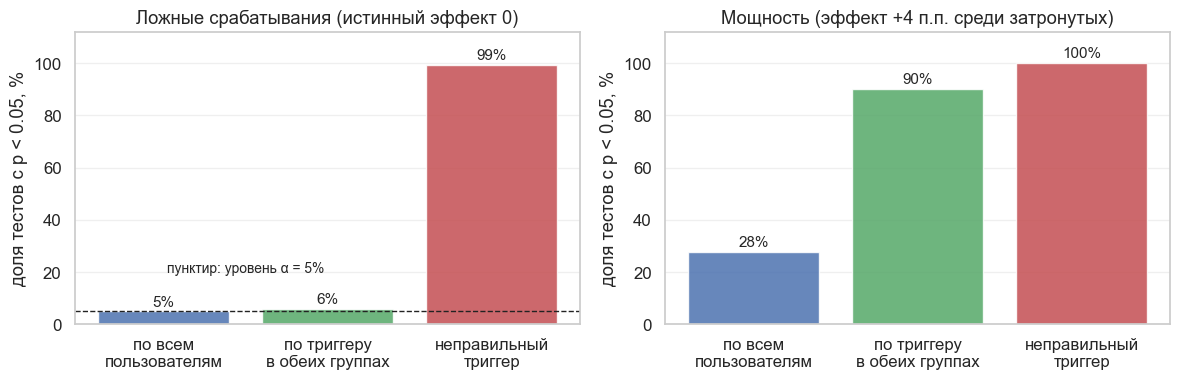

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = ['по всем\nпользователям', 'по триггеру\nв обеих группах', 'неправильный\nтриггер']
colors = [BLUE, GREEN, RED]
for ax, case, title in ((axes[0], null_case, 'Ложные срабатывания (истинный эффект 0)'), (axes[1], effect_case, 'Мощность (эффект +4 п.п. среди затронутых)')):
    values = [100 * case[k][1] for k in ('itt', 'trigger', 'wrong')]
    ax.bar(labels, values, color=colors, alpha=.85)
    for k, value in enumerate(values):
        ax.text(k, value + 2, f'{value:.0f}%', ha='center', fontsize=11)
    ax.set_ylim(0, 112)
    ax.set_ylabel('доля тестов с p < 0.05, %')
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].text(.5, 20, 'пунктир: уровень α = 5%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Три вывода.

* **Анализ по всем пользователям честен, но слаб:** уровень значимости держит (5%), но при эффекте, разбавленном в 12 раз, находит его лишь в 28% тестов.
* **Анализ по триггеру с одинаковым определением в группах** тоже держит уровень значимости (6%) и находит эффект в 90% тестов.
* **Неправильный триггер ломает всё:** он «находит» эффект в 99% тестов, даже когда его нет (среднюю оценку +6 п.п. при нулевом эффекте). Условие «увидел баннер» зависит от поведения после назначения, поэтому в тесте остаются самые вовлечённые, и разницу создаёт отбор, а не баннер.

Чтобы пересчитать эффект на триггерной подвыборке в эффект на всех пользователей, нужна **формула разбавления** (Deng, Hu, [WSDM 2015](https://exp-platform.com/dilution/)). Для аддитивной user-level метрики, например конверсии, и в предположении, что на незатронутых пользователей эффекта нет, она проста: Δ_overall = Δ_trigger × N_trigger / N. Для ratio-метрик нужны дополнительные множители, и авторы предупреждают, что на практике часто применяют приближённые или неверные формулы. Они предлагают объединить оценку по триггеру и пересчёт в один анализ, что даёт несмещённую оценку общего эффекта с большей мощностью.

In [19]:
trial = trigger_trial(np.random.default_rng(21))
delta_tr, se_tr, _ = trial['trigger']
delta_itt, se_itt, _ = trial['itt']
share = trial['share']
print(f'Доля затронутых: {100 * share:.1f}%')
print(f'Эффект по триггеру: {100 * delta_tr:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr):+.2f}; {100 * (delta_tr + 1.96 * se_tr):+.2f})')
print(f'Разбавленный на всех (Δ × доля): {100 * delta_tr * share:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr) * share:+.2f}; {100 * (delta_tr + 1.96 * se_tr) * share:+.2f})')
print(f'Прямая оценка по всем:           {100 * delta_itt:+.2f} п.п. (95% ДИ {100 * (delta_itt - 1.96 * se_itt):+.2f}; {100 * (delta_itt + 1.96 * se_itt):+.2f})')

Доля затронутых: 7.9%
Эффект по триггеру: +2.92 п.п. (95% ДИ +0.48; +5.35)
Разбавленный на всех (Δ × доля): +0.23 п.п. (95% ДИ +0.04; +0.42)
Прямая оценка по всем:           +0.08 п.п. (95% ДИ -0.41; +0.57)


Истинный эффект на всех пользователей равен 0.04 × 0.08 = 0.32 п.п. Обе оценки с ним согласуются, но интервал разбавленной оценки примерно в 2.6 раза уже прямого: именно в этом выигрыш триггера. Использовать его честно можно, только если мы заранее логируем условие триггера для обеих групп и определяем его по данным **до назначения** (или по признакам, на которые воздействие повлиять не может).

#### Проверьте себя

**Ситуация 4.** В тесте 50/50 SRM нет. Метрика «среднее число заказов на активного пользователя» упала на 5%, а число заказов на пользователя не изменилось. Что проверить в первую очередь?

<details>
<summary>Ответ</summary>

«Активный пользователь» определяется поведением после назначения: это тот, кто сделал хотя бы одно действие. Если изменение повлияло на то, сколько пользователей стали активными (например, новые слабоактивные пользователи начали заходить), знаменатель меняется, и метрика сравнивает разные наборы людей. Проверяем число активных пользователей в группах (метрический SRM), смотрим числитель и знаменатель отдельно и опираемся на метрику, посчитанную на всех пользователях, которым назначено воздействие.
</details>

### Потеря телеметрии

Клиентские события приходят на сервер не все: мобильное приложение копит их в буфере и отправляет пачкой при подходящей сети, а если буфер переполняется, старые события теряются. Если потеря в группах разная, метрики на клиентских событиях смещены.

Так было в эксперименте Skype из той же статьи: новый протокол пушей оставлял приложение «проснувшимся» на пару секунд дольше, этого хватало, чтобы чаще успеть отправить буфер. В тесте потеряно было меньше событий, и звонковые метрики значимо изменились, хотя звонки эксперимент затрагивать не должен был. Метрики двигались непохоже на обычное улучшение или ухудшение: одни сильно, а связанные с ними не двигались вовсе.

Моделируем: в нашем кейсе изменили способ доставки событий. Реальное число заказов не изменилось, но в тесте теряется 20% клиентских событий вместо 35%.

In [16]:
def simulate_telemetry(rng, n=20000, loss=(.35, .20)):
    """Реальные заказы одинаковы в группах; клиентский лог теряет часть событий, потеря в группах разная."""
    rows = {}
    for arm, rate in zip(('контроль', 'тест'), loss):
        true_orders = rng.poisson(3, n)
        logged = rng.binomial(true_orders, 1 - rate)
        rows[arm] = dict(server=true_orders, client=logged)
    return rows


tele = simulate_telemetry(np.random.default_rng(4))
c, t = tele['контроль'], tele['тест']
client_eff = rel_effect(c['client'].astype(float), t['client'].astype(float))
server_eff = rel_effect(c['server'].astype(float), t['server'].astype(float))
users_with = [np.mean(x['client'] > 0) for x in (c, t)]
chi = st.chi2_contingency([[np.sum(x['client'] > 0), np.sum(x['client'] == 0)] for x in (c, t)])
print(f'Заказы на пользователя по клиентскому логу: {pct(client_eff[0])} (SE {100 * client_eff[1]:.1f} п.п.)')
print(f'Заказы на пользователя на сервере:          {pct(server_eff[0])} (SE {100 * server_eff[1]:.1f} п.п.)')
print(f'Доля пользователей хотя бы с одним клиентским заказом: {100 * users_with[0]:.1f}% и {100 * users_with[1]:.1f}%, p = {chi[1]:.1e}')

Заказы на пользователя по клиентскому логу: +22.9% (SE 0.8 п.п.)
Заказы на пользователя на сервере:          +0.5% (SE 0.6 п.п.)
Доля пользователей хотя бы с одним клиентским заказом: 86.3% и 91.1%, p = 1.4e-51


По клиентскому логу тест «поднял» заказы на 23%, а на сервере разницы нет (+0.5% при стандартной ошибке 0.6 п.п.). Заметить это помогают три проверки.

* **Сверка клиентских событий с серверными** (при возможности). Клиентский лог может терять и дублировать события, а сервер фиксирует каждую оплату.
* **Метрики качества данных:** доля пользователей, у которых вообще есть хоть одно событие, и число событий на пользователя в группах. Здесь они значимо различаются: хотя бы одно клиентское событие есть у 86% пользователей в контроле и у 91% в тесте.
* **Непохожий узор.** Если одни метрики двигаются сильно, а связанные с ними нет, подозрение падает на измерение, а не на поведение.

Телеметрия, на которой потеря различается, делает практически недействительными все метрики, посчитанные по затронутым событиям.

### Чек-лист доверия к тесту

Все ловушки занятия складываются в последовательность проверок. Ссылки ведут к занятиям, где соответствующая тема разобрана подробнее.

| Когда | Что проверить | Где разобрано |
|---|---|---|
| До запуска | У теста одна OEC, а не набор «что-нибудь да выстрелит». OEC проверена на корпусе прошлых тестов (чувствительность и согласие с целью). | это занятие |
| До запуска | Заданы guardrail-метрики и контрметрика для метрики-цели. Они определены до того, как видны данные. | это занятие, [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7) |
| До запуска | Если анализ по триггеру, условие триггера логируется в обеих группах и определяется до назначения. | это занятие |
| До запуска | Длительность не короче полного недельного цикла и затухания новизны; план по доле теста фиксирован. | это занятие, [2.П1](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/2.%20%D0%9A%D0%B2%D0%B0%D0%B7%D0%B8-%D1%8D%D0%BA%D1%81%D0%BF%D0%B5%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5) |
| До запуска | Мощность и MDE посчитаны, проверка критерия на A/A сделана. | [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.06](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/06.%20%D0%9E%D0%BF%D0%B0%D1%81%D0%BD%D0%BE%D1%81%D1%82%D1%8C%20%D0%BC%D0%B0%D0%BB%D0%BE%D0%B9%20%D0%BC%D0%BE%D1%89%D0%BD%D0%BE%D1%81%D1%82%D0%B8.%20%D0%9E%D1%88%D0%B8%D0%B1%D0%BA%D0%B8%20S%20%D0%B8%20M%20%D1%82%D0%B8%D0%BF%D0%BE%D0%B2) |
| Во время | SRM на уровне пользователей проверяется регулярно, при изменении доли теста внутри каждого периода. | [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.П2](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5) |
| Во время | Промежуточные результаты не используются для остановки без специальных методов. | [2.01](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/2.%20%D0%9A%D0%B2%D0%B0%D0%B7%D0%B8-%D1%8D%D0%BA%D1%81%D0%BF%D0%B5%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5) |
| После | Сначала качество данных: SRM, число событий на пользователя в группах, сверка с серверным логом. | это занятие |
| После | Потом OEC, потом guardrail-метрики, потом диагностические. | это занятие |
| После | Сегменты заранее перечислены, поправка на множественность применена, эффекты в сегментах сравниваются через взаимодействие, доля сегмента проверена на равенство в группах. | это занятие, [1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7) |
| После | Если доля теста менялась, эффект считается внутри периодов с постоянной долей. | это занятие |
| После | Выбросы не искажают оценку, дисперсия снижена методами из 1.04. | [1.04](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/04.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D1%83%D1%81%D0%BA%D0%BE%D1%80%D0%B5%D0%BD%D0%B8%D1%8F%20AB%20%D1%82%D0%B5%D1%81%D1%82%D0%BE%D0%B2) |
| После | Результат «слишком хорош» или «странный»: эффект в разы больше MDE, метрики двигаются непохоже, эффект быстро затухает — ищем ошибку, а не запускаем. | это занятие |
| После запуска | Долгосрочный holdout сравнивает реальный эффект с тестовым. Результат пополняет корпус для проверки метрик. | это занятие |

## Часть 3. Как ускорить тест

Когда метрики выбраны, остаётся сократить длительность теста: главный рычаг здесь — дисперсия.

Если всё это уже согласовано, придётся действовать хитрее. Длительность теста напрямую зависит от размера выборки. Вспомним, как он считается для одной группы при равных дисперсиях:

$$
N = \frac{\left( \Phi^{-1}_{(1 - \alpha/2)} + \Phi^{-1}_{(1-\beta)} \right)^2 \times 2 \sigma^2}{MDE^2}
$$

Осталась дисперсия $\sigma^2$, и $N$ линейно зависит от неё: снизив дисперсию вдвое, мы вдвое сократим тест.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки.


In [2]:
def duration_demo(mde: float = 20.0, sigma: float = 300.0, variance_cut: float = 0.5, daily_users: int = 500) -> None:
    """Показывает, как снижение дисперсии сокращает необходимую выборку и длительность теста."""
    z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
    sizes = [2 * z_sum ** 2 * sigma ** 2 * share / mde ** 2 for share in (1.0, 1 - variance_cut)]
    days = [2 * size / daily_users for size in sizes]

    fig, ax = plt.subplots(figsize=(9, 2.6))
    bars = ax.barh(['С уменьшенной дисперсией', 'Исходная дисперсия'], days[::-1], color=[GREEN, GRAY])
    ax.bar_label(bars, labels=[f'{d:.0f} дн. ({s:,.0f} на группу)' for d, s in zip(days[::-1], sizes[::-1])], padding=4)
    ax.set_xlim(0, days[0] * 1.45)
    ax.set_xlabel('Длительность теста, дни')
    ax.set_title(f'Дисперсия ниже на {variance_cut:.0%}: тест короче на {variance_cut:.0%}')
    plt.tight_layout()
    plt.show()


interact(duration_demo,
         mde=FloatSlider(value=20, min=5, max=100, step=5, description='MDE'),
         sigma=FloatSlider(value=300, min=50, max=1000, step=50, description='σ'),
         variance_cut=FloatSlider(value=0.5, min=0, max=0.9, step=0.05, description='Снижение σ²'),
         daily_users=IntSlider(value=500, min=100, max=5000, step=100, description='Трафик/день'));


## Методы уменьшения дисперсии

| Метод | Что делает | Что для него нужно |
|---|---|---|
| Очистка от выбросов | Ограничивает влияние экстремальных значений | Порог или список пользователей, не зависящие от воздействия |
| Стратификация | Убирает дисперсию между сегментами | Сегменты, известные до теста |
| Бакетизация | **Не снижает дисперсию эффекта**, ускоряет вычисления | Случайное разбиение пользователей на бакеты |
| Линеаризация | **Не снижает дисперсию сама**, делает метрику отношения пользовательской | Числитель и знаменатель по пользователям |
| VWE | Даёт больший вес менее шумным пользователям | История поведения пользователя |
| CUPED | Вычитает объяснимую ковариатой часть метрики | Ковариата, не зависящая от воздействия |
| Predictive CUPED, CUPAC, MLRATE | Строят ковариату с помощью модели | Признаки до теста и правильная схема обучения |


### [Стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/)


Стратификация снижает дисперсию за счёт дополнительной информации о пользователях.

Для понимания стратификации введём несколько определений:

* **Популяция** – все пользователи (или объекты), на которых мы можем повлиять экспериментом. Например, 10 тысяч активных пользователей интернет-магазина.
* **Ковариата** – метрика, которая:
    * коррелирует с целевой метрикой;
    * может быть измерена до начала эксперимента;
    * не зависит от воздействия.

  Для экспериментов с людьми это пол, возраст, город, операционная система. Для магазинов — торговая площадь или режим работы.
* **Страты** – непересекающиеся подмножества популяции, каждое со своим набором значений ковариат.

Дисперсия метрики раскладывается на сумму дисперсии *внутри* страт и дисперсии *между* стратами (закон полной дисперсии):

$$
\sigma^2 = \sum_{k=1}^K w_k \sigma_k^2 + \sum_{k=1}^K w_k (\mu_k - \mu)^2
$$

Стратификация **убирает вторую часть**, поэтому общая дисперсия оценки снижается. Есть два подхода: стратифицированное сэмплирование и постстратификация. Посчитаем оба на примере двух равных страт со средними 2000 и 3000.


#### Стратифицированное сэмплирование

**Стратифицированное сэмплирование (пред-стратификация)** – способ формировать контрольную и экспериментальную группы так, чтобы доли страт в них были равны долям страт в популяции. Для этого определяем нужное число представителей каждой страты и случайно отбираем их из неё.

<br></br>

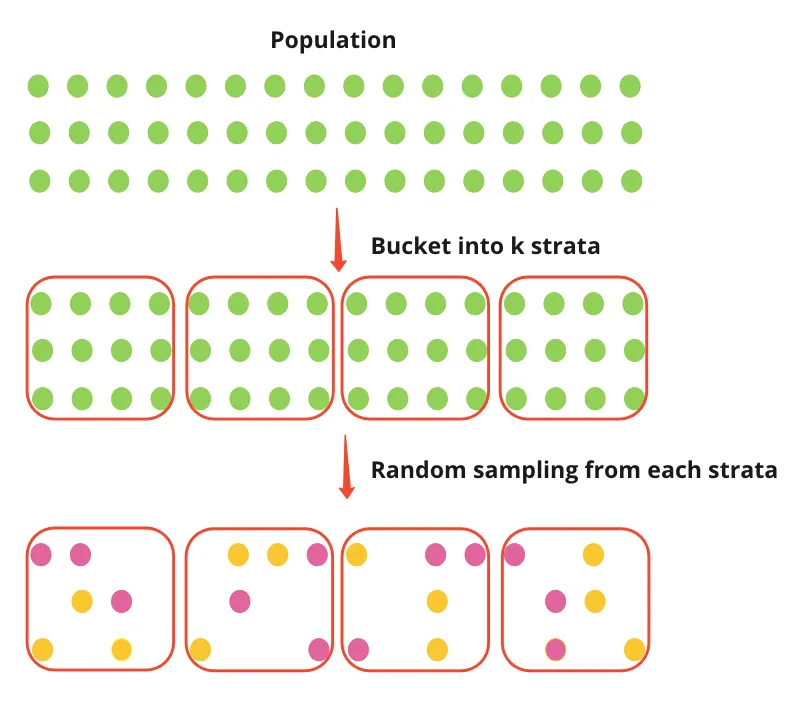


Дисперсия: 640,625 = 390,625 (внутри страт) + 250,000 (между стратами)
Расчётный объём выборки на группу: 1006



                                       Ошибка I рода  Мощность  SD оценки  Средняя SE
Случайно, обычное среднее                      0.048     0.791     35.674      35.674
Страт. сэмплирование, обычное среднее          0.012     0.854     27.518      35.685
Страт. сэмплирование, страт. среднее           0.054     0.952     28.241      27.878
Постстратификация                              0.052     0.946     28.013      27.862


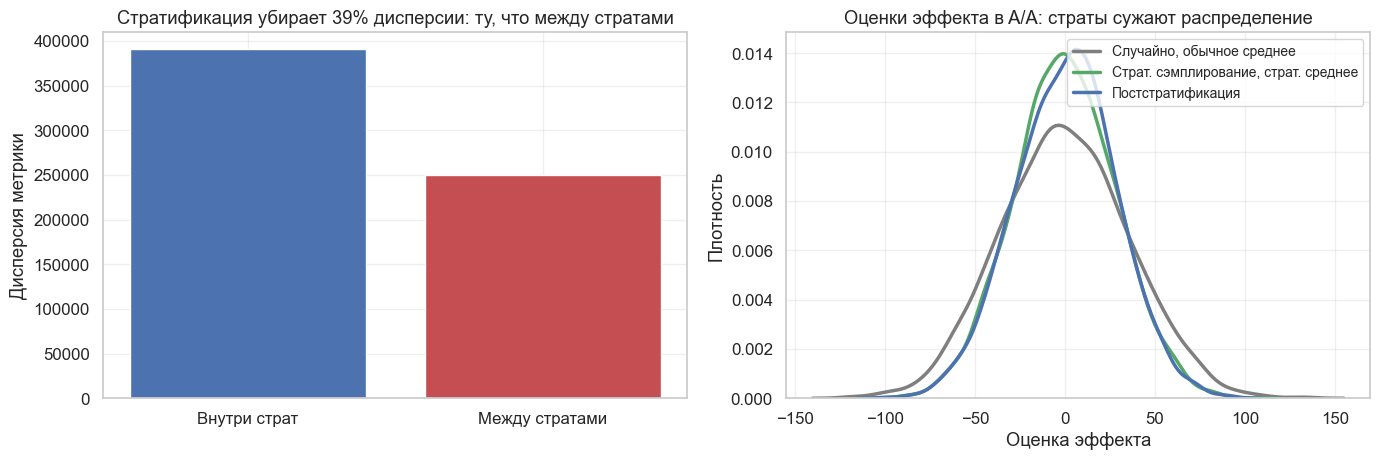

In [5]:
STRAT_CONFIG = {
    "alpha": ALPHA,
    "beta": 0.2,
    "effect": 100.0,
    "weights": (0.5, 0.5),  # доли страт в популяции
    "means": (2_000.0, 3_000.0),
    "stds": (625.0, 625.0),
}
strat_weights = np.array(STRAT_CONFIG["weights"])
strat_means = np.array(STRAT_CONFIG["means"])
strat_stds = np.array(STRAT_CONFIG["stds"])

# Общая дисперсия метрики: среднее дисперсий внутри страт + разброс средних между стратами
overall_mean = strat_weights @ strat_means
var_within = strat_weights @ strat_stds ** 2
var_between = strat_weights @ (strat_means - overall_mean) ** 2
var_total = var_within + var_between

z_sum = stats.norm.ppf(1 - STRAT_CONFIG["alpha"] / 2) + stats.norm.ppf(1 - STRAT_CONFIG["beta"])
strat_sample_size = int(np.ceil(2 * z_sum ** 2 * var_total / STRAT_CONFIG["effect"] ** 2))
print(f'Дисперсия: {var_total:,.0f} = {var_within:,.0f} (внутри страт) + {var_between:,.0f} (между стратами)')
print(f'Расчётный объём выборки на группу: {strat_sample_size}\n')


def generate_group(rng: np.random.Generator, size: tuple[int, int], stratified: bool, effect: float = 0.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и принадлежность к первой страте для группы с фиксированными или случайными долями страт."""
    if stratified:
        in_first = np.broadcast_to(np.arange(size[1]) < round(size[1] * strat_weights[0]), size)
    else:
        in_first = rng.random(size) < strat_weights[0]
    means = np.where(in_first, strat_means[0], strat_means[1])
    stds = np.where(in_first, strat_stds[0], strat_stds[1])
    return rng.normal(means + effect, stds), in_first


def plain_estimate(y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает обычное среднее и выборочную дисперсию метрики."""
    return y.mean(axis=1), y.var(axis=1, ddof=1)


def strat_estimate(y: np.ndarray, in_first: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает стратифицированное среднее и взвешенную дисперсию внутри страт."""
    mean_one, var_one, _ = masked_mean_var(y, in_first)
    mean_two, var_two, _ = masked_mean_var(y, ~in_first)
    return (strat_weights[0] * mean_one + strat_weights[1] * mean_two,
            strat_weights[0] * var_one + strat_weights[1] * var_two)


def simulate_strat(n: int, n_simulations: int = 4_000, batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает способы формирования групп и оценки среднего на A/A и A/B."""
    rng = np.random.default_rng(42)
    # Название: (стратифицированное сэмплирование, стратифицированное среднее)
    schemes = {
        'Случайно, обычное среднее': (False, False),
        'Страт. сэмплирование, обычное среднее': (True, False),
        'Страт. сэмплирование, страт. среднее': (True, True),
        'Постстратификация': (False, True),
    }
    result = {name: {'aa': [], 'ab': [], 'delta': [], 'se': []} for name in schemes}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', STRAT_CONFIG['effect'])):
            for name, (stratified, use_strat_mean) in schemes.items():
                y_c, first_c = generate_group(rng, (batch, n), stratified)
                y_t, first_t = generate_group(rng, (batch, n), stratified, effect)
                mean_c, var_c = strat_estimate(y_c, first_c) if use_strat_mean else plain_estimate(y_c)
                mean_t, var_t = strat_estimate(y_t, first_t) if use_strat_mean else plain_estimate(y_t)
                delta, se = mean_t - mean_c, np.sqrt((var_c + var_t) / n)
                result[name][key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'aa':
                    result[name]['delta'].append(delta)
                    result[name]['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


strat_results = simulate_strat(strat_sample_size)
print(pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in strat_results.items()
}).T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(['Внутри страт', 'Между стратами'], [var_within, var_between], color=[BLUE, RED])
axes[0].set_title(f'Стратификация убирает {var_between / var_total:.0%} дисперсии: ту, что между стратами')
axes[0].set_ylabel('Дисперсия метрики')
styles = {'Случайно, обычное среднее': GRAY, 'Страт. сэмплирование, страт. среднее': GREEN, 'Постстратификация': BLUE}
for name, color in styles.items():
    sns.kdeplot(strat_results[name]['delta'], ax=axes[1], label=name, color=color, linewidth=2.5)
axes[1].set_title('Оценки эффекта в A/A: страты сужают распределение')
axes[1].set_xlabel('Оценка эффекта')
axes[1].set_ylabel('Плотность')
axes[1].legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


Стратифицированное сэмплирование сильно уменьшило вероятности ошибок I и II рода, но это не совсем тот тест, который мы хотели. Мы планировали уровень значимости 0.05, а фактическая ошибка I рода равна 0.013. Распределение оценок эффекта стало уже: его реальное стандартное отклонение равно 27.5. Но t-тест не знает, что группы собраны не случайно, и считает завышенную стандартную ошибку (35.7). Вернуть тест на нужный уровень значимости поможет стратифицированное среднее.


#### Стратифицированное среднее

Оно вычисляется как взвешенная сумма средних каждой страты, где веса – доли страт в популяции.

Пусть $Y$ — целевая метрика, $k$ — индекс страты, $w_k$ — доля страты $k$ в популяции, $\bar{Y}_k$ — выборочное среднее метрики в страте $k$. Тогда стратифицированное среднее равно

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k
$$

Обратим внимание на два свойства.

* При стратифицированном сэмплировании ($n_k = w_k n$) стратифицированное среднее совпадает с выборочным:

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k = \sum_{k=1}^K w_k \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \sum_{k=1}^K \frac{n_k}{n} \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} Y_{kj} = \bar{Y}
$$

* Обычное и стратифицированное средние — несмещённые оценки одной и той же величины $\mu$. Для стратифицированного среднего при случайном сэмплировании это верно, если в каждую страту попало хотя бы одно наблюдение:

$$
\mathbb{E}(\bar{Y}) = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} \mathbb{E} (Y_{kj}) = \mu, \qquad
\mathbb{E}(\bar{Y}_{strat}) = \sum_{k=1}^K w_k \mathbb{E}(\bar{Y}_{k}) = \sum_{k=1}^K w_k \mu_{k} = \mu
$$

Различаются они **дисперсией**. Для стратифицированного среднего при $n_k = w_k n$

$$
\mathbb{V}(\bar{Y}_{strat}) = \frac{1}{n} \sum_{k=1}^K w_k \sigma_k^2
$$

Подставив оценки $\hat{\sigma}_k^2$, получим статистику теста. При большом $n$ она приблизительно нормальна:

$$
t = \frac{\bar{Y}_{strat, B} - \bar{Y}_{strat, A}}{\sqrt{\hat{\mathbb{V}}(\bar{Y}_{strat, A}) + \hat{\mathbb{V}}(\bar{Y}_{strat, B})}} \approx \mathcal{N}(0, 1)
$$

С такой статистикой ошибка I рода в таблице выше вернулась к 0.054, а мощность выросла с 0.791 до 0.952. Под стратификацией обычно и понимают сочетание стратифицированного сэмплирования и стратифицированного среднего.


#### Постстратификация

**Постстратификация** – подход, при котором группы формируются случайно, а для оценки среднего используется **стратифицированное среднее**. Он нужен, когда управлять составом групп нельзя, и на практике применяется чаще: достаточно знать страту каждого пользователя на момент анализа.

Запишем дисперсии среднего для трёх схем:

$$
\mathbb{V}_{rand}(\bar{Y}) = \frac{1}{n} \sum_k w_k \sigma_k^2 + \frac{1}{n} \sum_k w_k (\mu_k - \mu)^2, \qquad
\mathbb{V}_{strat}(\bar{Y}_{strat}) = \frac{1}{n} \sum_k w_k \sigma_k^2
$$

$$
\mathbb{V}_{post}(\bar{Y}_{strat}) \approx \mathbb{V}_{strat}(\bar{Y}_{strat}) + \frac{1}{n^2} \sum_k (1 - w_k) \sigma_k^2
$$

Плата за случайный состав групп имеет порядок $1/n^2$, а выигрыш — $1/n$. Поэтому на больших выборках постстратификация почти не уступает стратификации, как и в нашей таблице (0.052 и 0.946). Обычно

$$
\mathbb{V}_{strat}(\bar{Y}_{strat}) \le \mathbb{V}_{post}(\bar{Y}_{strat}) \le \mathbb{V}_{rand}(\bar{Y})
$$

но правое неравенство не гарантировано: при малых $n$, слабых различиях между стратами или большом их числе постстратификация может оказаться хуже обычного среднего. На практике также следите, чтобы страты были определены **до** теста, чтобы воздействие не могло перевести пользователя из страты в страту, а в каждой группе были представители всех страт.

<br></br>

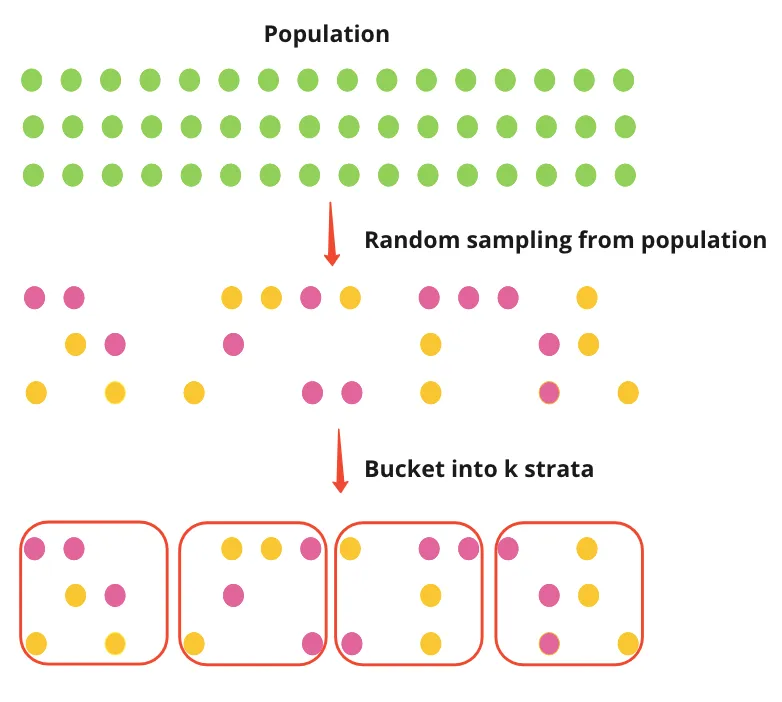

**Попробуйте сами.** Установите разнос страт 0, $n$ = 20 и увеличьте число страт: постстратификация станет хуже случайного разбиения.


In [6]:
def strat_variance_demo(between_gap: float = 1000.0, n: int = 1000, strat_std: float = 625.0, n_strata: int = 2) -> None:
    """Сравнивает теоретические дисперсии среднего при случайном разбиении, стратификации и постстратификации."""
    weights = np.full(n_strata, 1 / n_strata)
    means = np.linspace(-between_gap / 2, between_gap / 2, n_strata)
    between = weights @ means ** 2
    v_strat = strat_std ** 2 / n
    v_rand = v_strat + between / n
    v_post = v_strat + (1 - weights).sum() * strat_std ** 2 / n ** 2

    fig, ax = plt.subplots(figsize=(9, 3.2))
    labels = ['Случайное разбиение', 'Постстратификация', 'Стратифицированное сэмплирование']
    values = np.array([v_rand, v_post, v_strat])[::-1]
    bars = ax.barh(labels[::-1], values, color=[GREEN, BLUE, GRAY])
    ax.bar_label(bars, labels=[f'{v / v_rand:.1%} от случайного' for v in values], padding=4)
    ax.set_xlim(0, values.max() * 1.35)
    ax.set_xlabel('Дисперсия выборочного среднего')
    ax.set_title(f'n = {n}, страт: {n_strata}')
    plt.tight_layout()
    plt.show()


interact(strat_variance_demo,
         between_gap=FloatSlider(value=1000, min=0, max=3000, step=100, description='Разнос страт'),
         n=IntSlider(value=1000, min=20, max=2000, step=20, description='n'),
         strat_std=FloatSlider(value=625, min=100, max=1500, step=25, description='σ в страте'),
         n_strata=IntSlider(value=2, min=2, max=20, step=1, description='Страт'));


### [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/)


**CUPED (Controlled-experiment Using Pre-Experiment Data)** ([Deng et al., 2013](https://doi.org/10.1145/2433396.2433413)) — высокоэффективный метод снижения дисперсии метрик. Его идея — вычесть из теста и контроля нечто такое, чтобы математическое ожидание разницы осталось прежним, а дисперсия уменьшилась.

Для этого нужна ковариата — метрика, скоррелированная с целевой и не зависящая от эксперимента. Чаще всего это значение той же метрики на периоде до эксперимента. Обозначим целевую метрику как $Y$, а ковариату как $X$.

Суть метода CUPED — в переходе от метрики $Y$ к метрике

$$
Y_{cuped} = Y - \theta (X - \bar{X}), \text{ где } \theta - \text{некоторое число, а } \bar{X} - \text{среднее ковариаты по обеим группам}
$$

Значения CUPED-метрики подаются в статистический критерий вместо исходных. Точечная оценка эффекта — разница средних CUPED-метрики в группах. При случайном распределении пользователей $\mathbb{E}(\bar{X}^{test}) = \mathbb{E}(\bar{X}^{ctrl})$, то есть в обеих группах в среднем вычитается одно и то же, и оценка эффекта не смещена. Оценка $\theta$ по тем же данным добавляет лишь пренебрежимо малое смещение.

Центрирование $X - \bar{X}$ на разницу средних не влияет, если $\theta$ в группах общий. Но оно сохраняет исходный уровень метрики, что нужно для относительного эффекта.

Посмотрим, как меняется дисперсия оценки среднего:

$$
\mathbb{V}(\overline{Y}_{cuped}) = \dfrac{\mathbb{V}\left(Y - \theta X\right)}{n} = \dfrac{\mathbb{V} (Y) - 2\theta\,\mathrm{cov}\left(Y,X\right) + \theta^2\mathbb{V} (X)}{n}
$$

Дисперсия квадратично зависит от $\theta$. Это парабола с точкой минимума

$$
\theta_0 = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}
$$

Минимальная дисперсия равна

$$
\min\left(\mathbb{V} (\overline{Y}_{cuped})\right) = \mathbb{V} (\overline{Y}) \cdot \left(1 - \rho^2\right), \qquad \text{где } \rho = \frac{\mathrm{cov}(Y,X)} {\sqrt{\mathbb{V} (Y) \mathbb{V} (X)}}
$$

Значит, размер выборки сокращается в $1 / (1 - \rho^2)$ раз. Чем сильнее ковариата коррелирует с метрикой, тем больше выигрыш.

**Алгоритм применения CUPED**

1. Вычислить значения метрики $Y$ для каждого пользователя в обеих группах.
2. Вычислить значения ковариаты $X$ для каждого пользователя в обеих группах.
3. Вычислить $\theta = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}$ по объединённым данным.
4. Для каждого пользователя вычислить $Y_{cuped} = Y - \theta (X - \bar{X})$.
5. Применить статистический тест к значениям CUPED-метрики.

**Новые пользователи.** Если у пользователя нет данных до эксперимента, ковариату заполняют одним и тем же правилом в обеих группах (например, средним или нулём). Оценка остаётся несмещённой, но для таких пользователей CUPED не даст выигрыша.


#### Симуляция


Дисперсия CUPED-метрики / исходной: 0.510
Теория 1 - ρ²:                      0.510


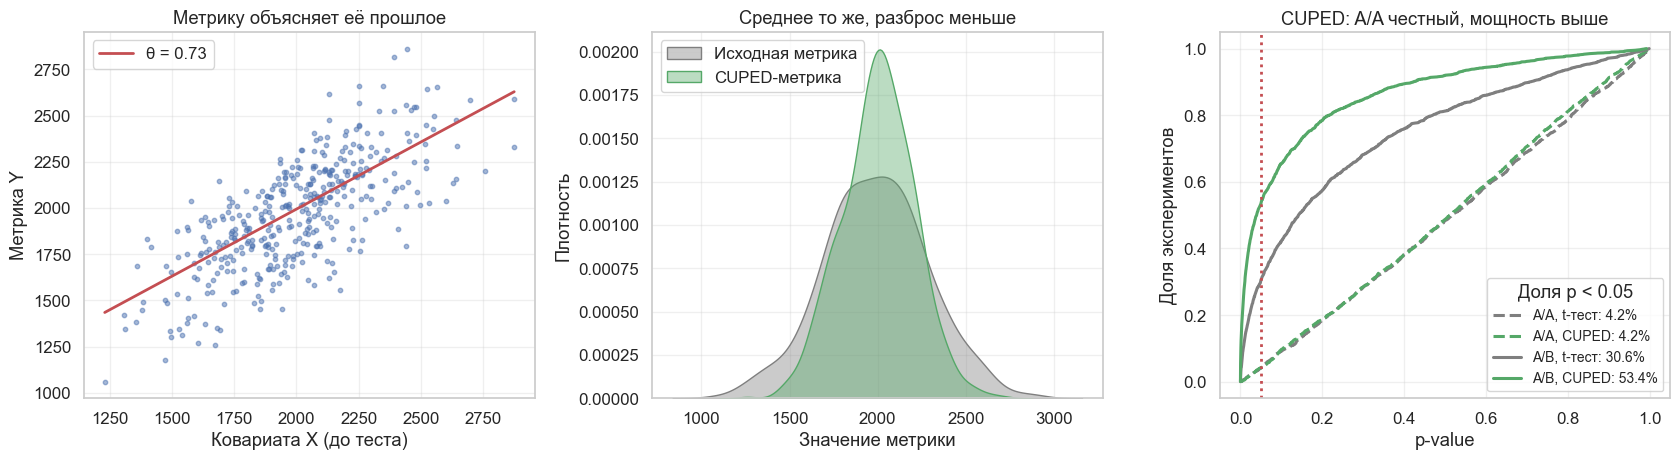

In [13]:
CUPED_CONFIG = {
    "n_simulations": 2_000,
    "sample_size": 1_000,
    "corr": 0.7,
    "effect": 20.0,
    "mean": 2_000.0,
    "sigma": 300.0,
}


def generate_metric_covariate(rng: np.random.Generator, size: tuple[int, int], corr: float, mean: float = 2_000.0,
                              sigma: float = 300.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и ковариату с заданной корреляцией."""
    covariate = rng.normal(0, 1, size)
    metric = corr * covariate + np.sqrt(1 - corr ** 2) * rng.normal(0, 1, size)
    return mean + sigma * metric, mean + sigma * covariate


def calculate_theta(metric: np.ndarray, covariate: np.ndarray) -> np.ndarray:
    """Считает коэффициент θ для CUPED по строкам."""
    cov_centered = covariate - covariate.mean(axis=1, keepdims=True)
    metric_centered = metric - metric.mean(axis=1, keepdims=True)
    return (cov_centered * metric_centered).sum(axis=1, keepdims=True) / (cov_centered ** 2).sum(axis=1, keepdims=True)


def apply_cuped(y_c: np.ndarray, x_c: np.ndarray, y_t: np.ndarray, x_t: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Считает CUPED-метрику обеих групп с общим θ и общим средним ковариаты."""
    pooled_x = np.hstack([x_c, x_t])
    theta = calculate_theta(np.hstack([y_c, y_t]), pooled_x)
    x_mean = pooled_x.mean(axis=1, keepdims=True)
    return y_c - theta * (x_c - x_mean), y_t - theta * (x_t - x_mean)


def plot_pvalue_ecdf(ax: plt.Axes, pvalues: dict[str, tuple[np.ndarray, str]]) -> None:
    """Рисует эмпирические функции распределения p-value: высота при α равна доле отклонений H0."""
    for name, (values, color) in pvalues.items():
        sorted_p = np.sort(values)
        style = '--' if 'A/A' in name else '-'
        ax.plot(sorted_p, np.arange(1, sorted_p.size + 1) / sorted_p.size, color=color, linestyle=style, linewidth=2.2,
                label=f'{name}: {np.mean(values < ALPHA):.1%}')
    ax.axvline(ALPHA, color=RED, linestyle=':', linewidth=2)
    ax.set_xlabel('p-value')
    ax.set_ylabel('Доля экспериментов')


rng = np.random.default_rng(42)
size = (CUPED_CONFIG['n_simulations'], CUPED_CONFIG['sample_size'])
params = (CUPED_CONFIG['corr'], CUPED_CONFIG['mean'], CUPED_CONFIG['sigma'])
y_c, x_c = generate_metric_covariate(rng, size, *params)
y_t, x_t = generate_metric_covariate(rng, size, *params)
y_e = y_t + CUPED_CONFIG['effect']

cuped_c, cuped_aa = apply_cuped(y_c, x_c, y_t, x_t)
cuped_c_ab, cuped_ab = apply_cuped(y_c, x_c, y_e, x_t)
cuped_pvalues = {
    'A/A, t-тест': (stats.ttest_ind(y_t, y_c, axis=1).pvalue, GRAY),
    'A/A, CUPED': (stats.ttest_ind(cuped_aa, cuped_c, axis=1).pvalue, GREEN),
    'A/B, t-тест': (stats.ttest_ind(y_e, y_c, axis=1).pvalue, GRAY),
    'A/B, CUPED': (stats.ttest_ind(cuped_ab, cuped_c_ab, axis=1).pvalue, GREEN),
}
print(f"Дисперсия CUPED-метрики / исходной: {cuped_c.var(axis=1).mean() / y_c.var(axis=1).mean():.3f}")
print(f"Теория 1 - ρ²:                      {1 - CUPED_CONFIG['corr'] ** 2:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(x_c[0, :400], y_c[0, :400], s=10, alpha=0.5, color=BLUE)
theta_line = calculate_theta(y_c[:1], x_c[:1])[0, 0]
grid = np.array([x_c[0, :400].min(), x_c[0, :400].max()])
axes[0].plot(grid, y_c[0].mean() + theta_line * (grid - x_c[0].mean()), color=RED, linewidth=2, label=f'θ = {theta_line:.2f}')
axes[0].set_title('Метрику объясняет её прошлое')
axes[0].set_xlabel('Ковариата X (до теста)')
axes[0].set_ylabel('Метрика Y')
axes[0].legend()
sns.kdeplot(y_c[0], ax=axes[1], color=GRAY, fill=True, alpha=0.4, label='Исходная метрика')
sns.kdeplot(cuped_c[0], ax=axes[1], color=GREEN, fill=True, alpha=0.4, label='CUPED-метрика')
axes[1].set_title('Среднее то же, разброс меньше')
axes[1].set_xlabel('Значение метрики')
axes[1].set_ylabel('Плотность')
axes[1].legend()
plot_pvalue_ecdf(axes[2], cuped_pvalues)
axes[2].set_title('CUPED: A/A честный, мощность выше')
axes[2].legend(fontsize=10, title='Доля p < 0.05', loc='lower right')
plt.tight_layout()
plt.show()


Дисперсия упала до теоретических $1 - \rho^2$. На правом графике штриховые линии (A/A) идут вдоль диагонали, а значит, ошибка I рода корректна. Сплошная зелёная линия выше серой: при том же размере выборки CUPED обнаруживает эффект чаще.

**Попробуйте сами.** Двигайте $\theta$ и найдите значения, при которых CUPED **увеличивает** дисперсию.


In [14]:
def cuped_demo(rho: float = 0.7, theta: float = 0.4) -> None:
    """Показывает зависимость дисперсии CUPED-метрики от θ при Var(X) = Var(Y) = 1."""
    thetas = np.linspace(-1, 1, 201)
    current = 1 - 2 * theta * rho + theta ** 2

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(thetas, 1 - 2 * thetas * rho + thetas ** 2, color=BLUE, linewidth=2.5)
    ax.scatter([theta], [current], color=RED, zorder=3, s=60, label=f'Ваш θ: дисперсия {current:.0%} от исходной')
    ax.scatter([rho], [1 - rho ** 2], color=GREEN, zorder=3, s=60, label=f'Оптимальный θ = ρ: {1 - rho ** 2:.0%}')
    ax.axhline(1, color=GRAY, linestyle='--', label='Без CUPED')
    ax.set_xlabel('θ')
    ax.set_ylabel('Var(Y - θX) / Var(Y)')
    ax.set_title('Неудачный θ может увеличить дисперсию')
    ax.legend()
    plt.tight_layout()
    plt.show()


interact(cuped_demo,
         rho=FloatSlider(value=0.7, min=-0.95, max=0.95, step=0.05, description='ρ'),
         theta=FloatSlider(value=0.4, min=-1, max=1, step=0.05, description='θ'));


Как зависит выигрыш от корреляции:


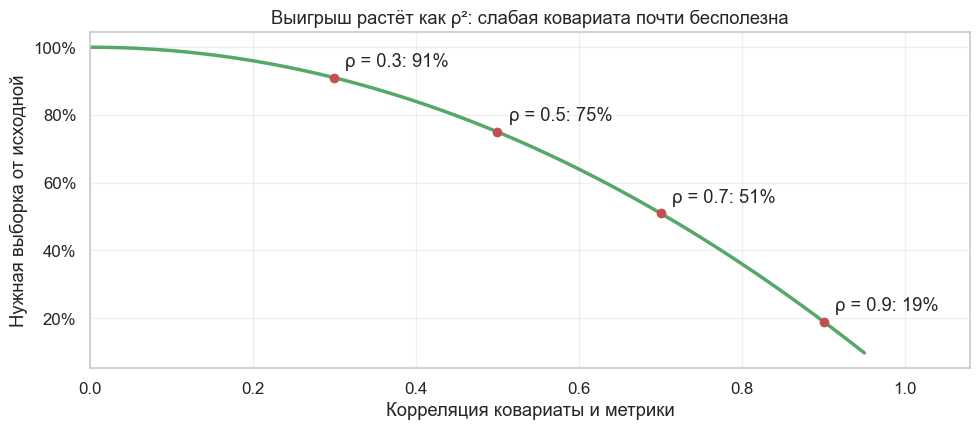

In [15]:
rhos = np.linspace(0, 0.95, 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rhos, 1 - rhos ** 2, color=GREEN, linewidth=2.5)
for rho in (0.3, 0.5, 0.7, 0.9):
    ax.scatter([rho], [1 - rho ** 2], color=RED, zorder=3)
    ax.annotate(f'ρ = {rho}: {1 - rho ** 2:.0%}', (rho, 1 - rho ** 2), textcoords='offset points', xytext=(8, 8))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(0, 1.08)
ax.set_xlabel('Корреляция ковариаты и метрики')
ax.set_ylabel('Нужная выборка от исходной')
ax.set_title('Выигрыш растёт как ρ²: слабая ковариата почти бесполезна')
plt.tight_layout()
plt.show()


**CUPED и регрессия.** Эффект CUPED с общим $\theta$ практически совпадает с коэффициентом при индикаторе группы в регрессии $Y = \alpha + \tau T + \theta X + \varepsilon$ (ANCOVA). Это помогает понимать и обобщать метод: несколько ковариат — это просто регрессия с несколькими признаками.


In [16]:
rng = np.random.default_rng(42)
y_c_one, x_c_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one, x_t_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one = y_t_one + 20

cuped_c_one, cuped_t_one = apply_cuped(y_c_one, x_c_one, y_t_one, x_t_one)
design = np.column_stack([
    np.ones(2_000),
    np.r_[np.zeros(1_000), np.ones(1_000)],
    np.r_[x_c_one[0], x_t_one[0]],
])
ols = sm.OLS(np.r_[y_c_one[0], y_t_one[0]], design).fit()

print(f'Эффект по CUPED:               {cuped_t_one.mean() - cuped_c_one.mean():.3f}')
print(f'Коэффициент при T в регрессии: {ols.params[1]:.3f}')


Эффект по CUPED:               36.876
Коэффициент при T в регрессии: 36.912


### [Линеаризация](https://www.researchgate.net/publication/322969314_Consistent_Transformation_of_Ratio_Metrics_for_Efficient_Online_Controlled_Experiments)


Метрика отношения (CTR, средний чек, клики на сессию) считается как отношение сумм, поэтому её наблюдения — это показы или заказы, а не пользователи. Один пользователь даёт много зависимых наблюдений, и обычный t-тест применять нельзя ([лекция 1.02](<../02. Введение в тестирование гипотез и дизайн AB/lecture.ipynb>)). Дисперсию можно посчитать дельта-методом ([практика 1.П1](<../../Практический блок/01. ЦПТ. Дельта метод. Построение оценок и доверительных интервалов/practice.ipynb>)), но с ним не работают методы вроде CUPED, которым нужна метрика на уровне пользователя.

**Линеаризация** ([Budylin et al., 2018](https://doi.org/10.1145/3159652.3159699)) решает именно эту задачу: превращает метрику отношения в **пользовательскую метрику**.

**Важно:** сама по себе линеаризация **не снижает дисперсию** и не делает тест мощнее дельта-метода, их p-value практически совпадают. Её ценность в том, что поверх новой метрики можно применить t-тест, CUPED и другие методы снижения дисперсии.

Для метрики отношения $\mathcal{R} = \frac{\sum_{u \in U} Y(u)}{\sum_{u \in U} X(u)}$ линеаризованная метрика равна

$$
Lin(u) = Y(u) - \mathcal{R}^{ctrl} X(u), \text{ где } \mathcal{R}^{ctrl} - \text{значение метрики отношения в контрольной группе}
$$

Посчитав $Lin(u)$ для каждого пользователя в обеих группах, сравниваем средние обычным t-тестом. Средняя метрика в контроле равна нулю, а разница средних связана с эффектом так:

$$
\overline{Lin}^{\,test} - \overline{Lin}^{\,ctrl} = \bar{X}^{test} \left( \mathcal{R}^{test} - \mathcal{R}^{ctrl} \right)
$$

Отсюда следуют две практические детали: знак эффекта всегда совпадает со знаком изменения исходной метрики, а чтобы получить эффект в единицах метрики отношения, разницу нужно поделить на $\bar{X}^{test}$. По той же причине MDE для линеаризованной метрики равен MDE метрики отношения, умноженному на средний знаменатель.

**Линеаризация с весами.** Пользователи с большим знаменателем могут вносить в метрику много шума. Чтобы снизить их влияние, наблюдения можно перевзвесить, например, на корень из знаменателя:

$$
\mathcal{R}_{rew} = \frac{\sum_u \sqrt{X(u)} \times \frac{Y(u)}{X(u)}}{\sum_u \sqrt{X(u)}}, \qquad
Lin_{rew}(u) = \sqrt{X(u)} \left( \frac{Y(u)}{X(u)} - \mathcal{R}_{rew}^{ctrl} \right)
$$

Это уже другая метрика с другими весами пользователей: такой вариант подходит для проверки гипотезы, но его эффект не равен эффекту на исходную метрику отношения.

Проверим всё это на CTR: у пользователей разная активность и разная склонность кликать, а воздействие поднимает CTR на 5%.


                              Ошибка I рода  Мощность
По показам, клики независимы          0.191     0.586
Среднее CTR пользователей             0.048     0.260
Дельта-метод                          0.052     0.340
Линеаризация                          0.052     0.346
Линеаризация с весами                 0.046     0.384
Линеаризация + CUPED                  0.048     0.462


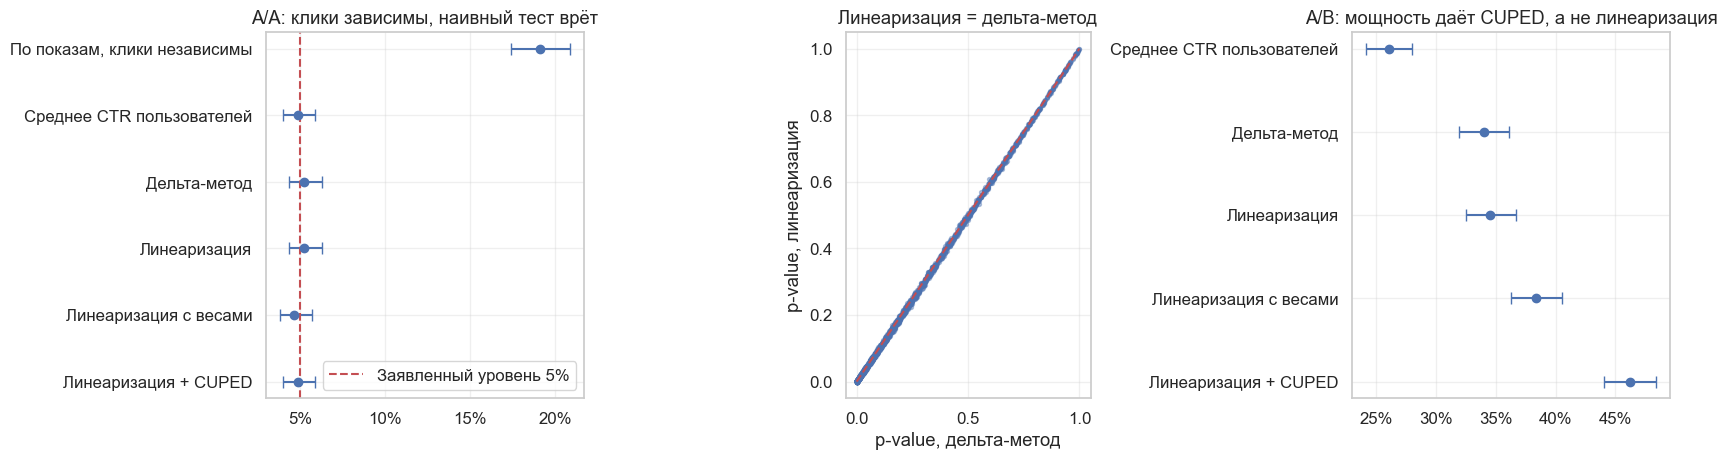

In [10]:
LIN_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 3_000,
    "uplift": 0.05,  # рост CTR на 5%
}


def generate_ctr_data(rng: np.random.Generator, size: tuple[int, int], uplift: float = 0.0) -> dict[str, np.ndarray]:
    """Генерирует просмотры и клики пользователей до и во время эксперимента."""
    activity = rng.gamma(1.0, 12.0, size)  # у пользователей разная активность
    ctr = rng.beta(2, 18, size) * np.clip(1.6 - 0.03 * activity, 0.4, 1.6)  # и разная склонность кликать
    views_pre = 1 + rng.poisson(activity)
    views = 1 + rng.poisson(activity)
    return {
        'views_pre': views_pre,
        'clicks_pre': rng.binomial(views_pre, ctr),
        'views': views,
        'clicks': rng.binomial(views, np.minimum(ctr * (1 + uplift), 1)),
    }


def ratio_delta_var(views: np.ndarray, clicks: np.ndarray) -> np.ndarray:
    """Считает дисперсию ratio-метрики дельта-методом по пользовательским суммам."""
    n = views.shape[1]
    mean_x, mean_y = views.mean(axis=1, keepdims=True), clicks.mean(axis=1, keepdims=True)
    ratio = mean_y / mean_x
    return ((clicks - ratio * views) ** 2).sum(axis=1) / (n - 1) / (n * mean_x[:, 0] ** 2)


def ratio_tests(control: dict[str, np.ndarray], pilot: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Возвращает p-value разных критериев для метрики отношения."""
    x_c, y_c, x_t, y_t = control['views'], control['clicks'], pilot['views'], pilot['clicks']
    r_c = y_c.sum(axis=1, keepdims=True) / x_c.sum(axis=1, keepdims=True)
    r_t = y_t.sum(axis=1, keepdims=True) / x_t.sum(axis=1, keepdims=True)
    delta = (r_t - r_c)[:, 0]

    # Клики как независимые испытания: типичная ошибка
    se_naive = np.sqrt(r_c[:, 0] * (1 - r_c[:, 0]) / x_c.sum(axis=1) + r_t[:, 0] * (1 - r_t[:, 0]) / x_t.sum(axis=1))
    se_delta = np.sqrt(ratio_delta_var(x_c, y_c) + ratio_delta_var(x_t, y_t))

    lin_c, lin_t = y_c - r_c * x_c, y_t - r_c * x_t

    w_c, w_t = np.sqrt(x_c), np.sqrt(x_t)
    r_rew = ((w_c * y_c / x_c).sum(axis=1) / w_c.sum(axis=1))[:, None]
    rew_c, rew_t = (y_c - r_rew * x_c) / w_c, (y_t - r_rew * x_t) / w_t

    # CUPED поверх линеаризации: ковариата — та же линеаризованная метрика на предпериоде
    r_pre = control['clicks_pre'].sum(axis=1, keepdims=True) / control['views_pre'].sum(axis=1, keepdims=True)
    cov_c = control['clicks_pre'] - r_pre * control['views_pre']
    cov_t = pilot['clicks_pre'] - r_pre * pilot['views_pre']
    pooled_lin, pooled_cov = np.hstack([lin_c, lin_t]), np.hstack([cov_c, cov_t])
    centered_cov = pooled_cov - pooled_cov.mean(axis=1, keepdims=True)
    theta = ((pooled_lin * centered_cov).sum(axis=1) / (centered_cov ** 2).sum(axis=1))[:, None]

    return {
        'По показам, клики независимы': z_pvalue(delta, se_naive),
        'Среднее CTR пользователей': stats.ttest_ind(y_t / x_t, y_c / x_c, axis=1).pvalue,
        'Дельта-метод': z_pvalue(delta, se_delta),
        'Линеаризация': stats.ttest_ind(lin_t, lin_c, axis=1).pvalue,
        'Линеаризация с весами': stats.ttest_ind(rew_t, rew_c, axis=1).pvalue,
        'Линеаризация + CUPED': stats.ttest_ind(lin_t - theta * cov_t, lin_c - theta * cov_c, axis=1).pvalue,
    }


def simulate_ratio(n_simulations: int, n_users: int, uplift: float, batch: int = 200) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает p-value всех критериев."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {'aa': {}, 'ab': {}}
    for _ in tqdm(range(n_simulations // batch), desc='Симуляции ratio-метрики'):
        for key, effect in (('aa', 0.0), ('ab', uplift)):
            control = generate_ctr_data(rng, (batch, n_users))
            pilot = generate_ctr_data(rng, (batch, n_users), effect)
            for name, pvalues in ratio_tests(control, pilot).items():
                result[key].setdefault(name, []).append(pvalues)
    return {key: {name: np.concatenate(values) for name, values in row.items()} for key, row in result.items()}


ratio_pvalues = simulate_ratio(**LIN_CONFIG)
print(pd.DataFrame({
    'Ошибка I рода': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['aa'].items()},
    'Мощность': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['ab'].items()},
}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
plot_rates(axes[0], {name: p < ALPHA for name, p in ratio_pvalues['aa'].items()}, 'A/A: клики зависимы, наивный тест врёт')
axes[1].scatter(ratio_pvalues['ab']['Дельта-метод'], ratio_pvalues['ab']['Линеаризация'], s=8, alpha=0.4, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=RED, linestyle='--')
axes[1].set_title('Линеаризация = дельта-метод')
axes[1].set_xlabel('p-value, дельта-метод')
axes[1].set_ylabel('p-value, линеаризация')
correct = [name for name in ratio_pvalues['ab'] if name != 'По показам, клики независимы']
plot_rates(axes[2], {name: ratio_pvalues['ab'][name] < ALPHA for name in correct}, 'A/B: мощность даёт CUPED, а не линеаризация', None)
plt.tight_layout()
plt.show()


Что видно по результатам:

* Если считать показы независимыми, ошибка I рода равна 19.1%. Это главная проблема, которую решают дельта-метод и линеаризация.
* Линеаризация и дельта-метод совпадают: точки на среднем графике лежат на диагонали, мощность 0.345 и 0.340.
* Среднее CTR пользователей — корректный тест, но **другой метрики**: каждый пользователь в нём весит одинаково, а не пропорционально показам. Поэтому и мощность другая (0.261), а значение метрики может заметно отличаться от общего CTR.
* Линеаризация с весами на этих данных мощнее (0.384), но это свойство данных, а не гарантия.
* Настоящий выигрыш даёт CUPED поверх линеаризации: мощность 0.462.

Проверим формулу перехода к единицам метрики отношения:


In [11]:
rng = np.random.default_rng(7)
control = generate_ctr_data(rng, (1, 200_000))
pilot = generate_ctr_data(rng, (1, 200_000), LIN_CONFIG['uplift'])

ratio_c = control['clicks'].sum() / control['views'].sum()
ratio_t = pilot['clicks'].sum() / pilot['views'].sum()
lin_c = control['clicks'] - ratio_c * control['views']
lin_t = pilot['clicks'] - ratio_c * pilot['views']

print(f"Эффект на CTR:                     {ratio_t - ratio_c:.5f}")
print(f"Эффект на линеаризованной метрике: {lin_t.mean() - lin_c.mean():.5f}")
print(f"Он же, делённый на X̄ теста:        {(lin_t.mean() - lin_c.mean()) / pilot['views'].mean():.5f}")


Эффект на CTR:                     0.00466
Эффект на линеаризованной метрике: 0.06045
Он же, делённый на X̄ теста:        0.00466


### [Очистка данных от выбросов](https://habr.com/ru/companies/avito/articles/571094/#:~:text=%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D0%B1%D0%BE%D1%80%D1%8C%D0%B1%D1%8B%20%D1%81%20%D0%B2%D1%8B%D0%B1%D1%80%D0%BE%D1%81%D0%B0%D0%BC%D0%B8%20%D0%B2%20%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85)


Чем больше выбросов, тем выше дисперсия и тем менее мощный у нас критерий. Поэтому аналитикам часто приходит в голову **убрать n% пользователей с самой большой (или самой маленькой) метрикой в тесте и контроле**.

Идея здравая, но подходить к ней нужно осторожно:

1. Неправильная реализация может исказить результаты эксперимента.
2. Убирая топ пользователей и принимая решение по остальным, мы неявно считаем, что топ-пользователи отреагируют на изменение так же, как остальные, или лучше. Это не всегда так, и это стоит проверять отдельно.

Сравним способы очистки на одних и тех же данных. Выручка пользователя скошена вправо, средняя выручка равна 1000. В A/B-тесте она вырастает у всех на 15%, так что истинный эффект равен 150. Отрезаем верхний 1%.


Истинный эффект на всю аудиторию: 150
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без очистки                                0.048     0.603         149.818     68.609      68.049
Свой порог в каждой группе                 0.083     0.699         137.360     61.150      54.037
Свой порог + поправка SE                   0.050     0.621         137.360     61.150      60.943
Общий порог по тесту и контролю            0.054     0.536         110.578     54.179      53.817
Порог по контролю                          0.054     0.466          98.138     51.777      51.878
Порог предпериода к метрике теста          0.056     0.518         104.315     51.841      51.800
Исключение по выручке до теста             0.048     0.603         147.653     67.386      66.918
Винзоризация порогом предпериода           0.051     0.623         132.991     59.072      58.753


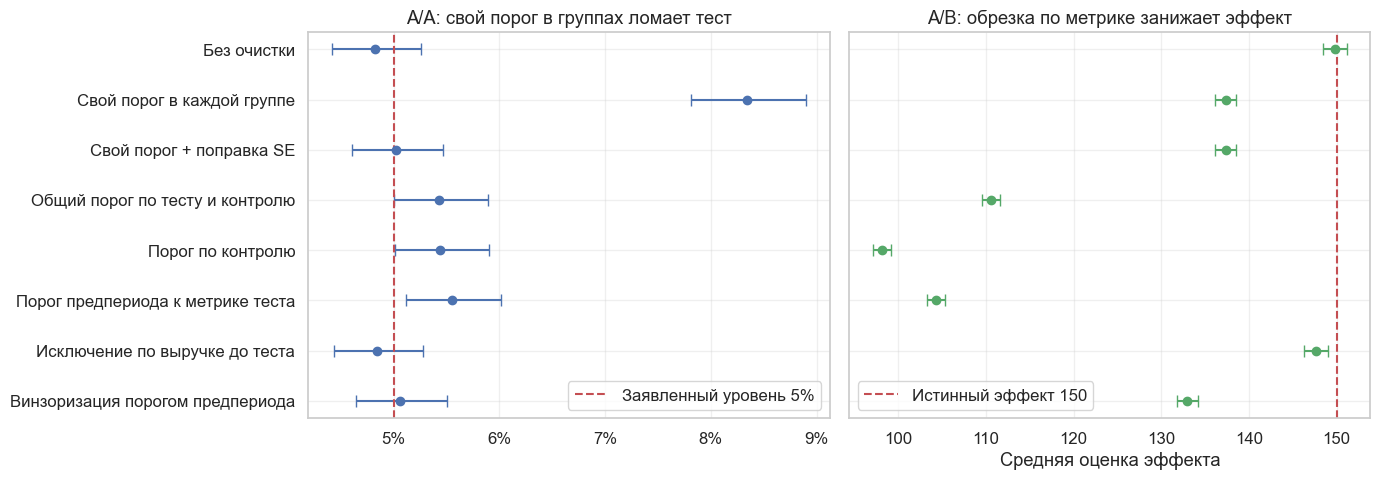

In [3]:
OUTLIER_CONFIG = {
    "n_simulations": 10_000,
    "sample_size": 1_000,
    "tail_share": 0.01,
    "lift": 1.15,  # эффект: выручка каждого пользователя выросла на 15%
}
OUTLIER_TRUE_EFFECT = 1_000 * (OUTLIER_CONFIG["lift"] - 1)


def generate_revenue(rng: np.random.Generator, size: tuple[int, int], lift: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует выручку пользователя до и во время эксперимента. Средняя выручка до эксперимента равна 1000."""
    activity = rng.gamma(2, 500, size)  # постоянная часть: активные пользователи тратят больше в оба периода
    return activity * rng.exponential(1, size), lift * activity * rng.exponential(1, size)


def clean_and_compare(pre_c: np.ndarray, y_c: np.ndarray, pre_t: np.ndarray, y_t: np.ndarray,
                      tail_share: float) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Применяет способы очистки и для каждого возвращает оценку эффекта и её стандартную ошибку."""
    level = 1 - tail_share
    n = y_c.shape[1]
    q_c = np.quantile(y_c, level, axis=1, keepdims=True)
    q_t = np.quantile(y_t, level, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), level, axis=1, keepdims=True)
    q_pre = np.quantile(np.hstack([pre_c, pre_t]), level, axis=1, keepdims=True)

    def compare(x_c, mask_c, x_t, mask_t):
        mean_c, var_c, n_c = masked_mean_var(x_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(x_t, mask_t)
        return mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)

    everyone = np.ones_like(y_c, dtype=bool)
    per_group = compare(y_c, y_c <= q_c, y_t, y_t <= q_t)
    # SE усечённого среднего, учитывающая случайность порога: дисперсия винзоризованной метрики / (1 - доля)^2
    yuen_var = (np.minimum(y_c, q_c).var(axis=1, ddof=1) + np.minimum(y_t, q_t).var(axis=1, ddof=1)) / level ** 2
    return {
        'Без очистки': compare(y_c, everyone, y_t, everyone),
        'Свой порог в каждой группе': per_group,
        'Свой порог + поправка SE': (per_group[0], np.sqrt(yuen_var / n)),
        'Общий порог по тесту и контролю': compare(y_c, y_c <= q_pooled, y_t, y_t <= q_pooled),
        'Порог по контролю': compare(y_c, y_c <= q_c, y_t, y_t <= q_c),
        'Порог предпериода к метрике теста': compare(y_c, y_c <= q_pre, y_t, y_t <= q_pre),
        'Исключение по выручке до теста': compare(y_c, pre_c <= q_pre, y_t, pre_t <= q_pre),
        'Винзоризация порогом предпериода': compare(np.minimum(y_c, q_pre), everyone, np.minimum(y_t, q_pre), everyone),
    }


def simulate_outliers(n_simulations: int, sample_size: int, tail_share: float, lift: float,
                      batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает оценки эффекта, SE и решения по каждому способу очистки."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {}
    for _ in range(n_simulations // batch):
        for key, group_lift in (('aa', 1.0), ('ab', lift)):
            pre_c, y_c = generate_revenue(rng, (batch, sample_size))
            pre_t, y_t = generate_revenue(rng, (batch, sample_size), group_lift)
            for name, (delta, se) in clean_and_compare(pre_c, y_c, pre_t, y_t, tail_share).items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


outlier_results = simulate_outliers(**OUTLIER_CONFIG)
outlier_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in outlier_results.items()
}).T
print(f'Истинный эффект на всю аудиторию: {OUTLIER_TRUE_EFFECT:.0f}')
print(outlier_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_rates(axes[0], {name: row['aa'] for name, row in outlier_results.items()}, 'A/A: свой порог в группах ломает тест')
names = list(outlier_results)[::-1]
axes[1].errorbar(outlier_table.loc[names, 'Оценка эффекта'], names,
                 xerr=1.96 * outlier_table.loc[names, 'SD оценки'] / np.sqrt(OUTLIER_CONFIG['n_simulations']),
                 fmt='o', color=GREEN, capsize=4)
axes[1].axvline(OUTLIER_TRUE_EFFECT, color=RED, linestyle='--', label=f'Истинный эффект {OUTLIER_TRUE_EFFECT:.0f}')
axes[1].set_title('A/B: обрезка по метрике занижает эффект')
axes[1].set_xlabel('Средняя оценка эффекта')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()


#### Нельзя чистить данные своим порогом в каждой группе

Самый очевидный способ — посчитать 99-й перцентиль в тесте, в контроле и отрезать всё, что выше, — даёт ошибку I рода 8.3% вместо 5%, то есть метод некорректен.

Дело в том, что порог оценён по тем же данным, которые мы затем сравниваем. Из-за шума он в каждой группе свой, и этот шум попадает в оценку эффекта, а t-тест о нём не знает: он считает порог заранее заданным. Поэтому средняя стандартная ошибка (54.0) занижена по сравнению с реальным разбросом оценки (61.1). Если учесть случайность порога (дисперсия винзоризованной метрики, делённая на $(1 - \text{доля})^2$, как в тесте Юэна), ошибка возвращается к 5.0%. Но оценивать мы будем уже разницу усечённых средних, а не эффект на всю аудиторию.

Чем больше отрезаем, тем сильнее проблема:


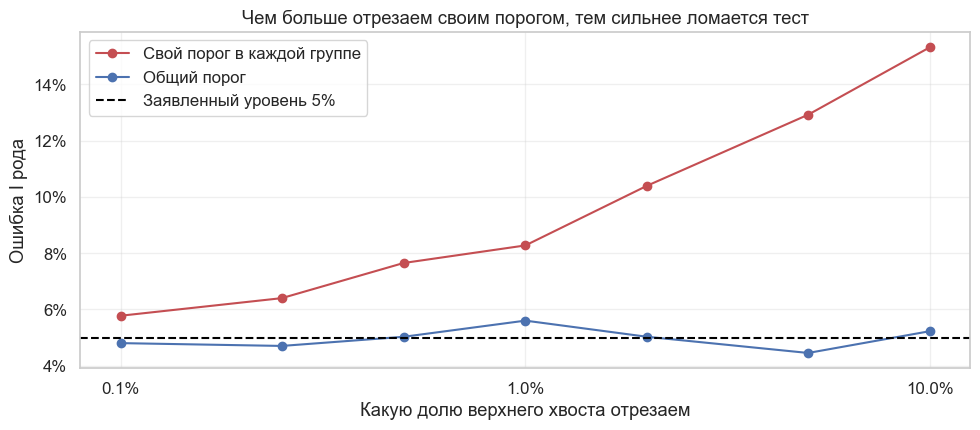

In [4]:
rng = np.random.default_rng(42)
tail_shares = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1])
per_group_fpr, pooled_fpr = [], []
for share in tail_shares:
    _, y_c = generate_revenue(rng, (4_000, 1_000))
    _, y_t = generate_revenue(rng, (4_000, 1_000))
    q_c = np.quantile(y_c, 1 - share, axis=1, keepdims=True)
    q_t = np.quantile(y_t, 1 - share, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), 1 - share, axis=1, keepdims=True)
    for store, mask_c, mask_t in ((per_group_fpr, y_c <= q_c, y_t <= q_t), (pooled_fpr, y_c <= q_pooled, y_t <= q_pooled)):
        mean_c, var_c, n_c = masked_mean_var(y_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(y_t, mask_t)
        store.append(np.mean(z_pvalue(mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)) < ALPHA))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tail_shares, per_group_fpr, 'o-', color=RED, label='Свой порог в каждой группе')
ax.plot(tail_shares, pooled_fpr, 'o-', color=BLUE, label='Общий порог')
ax.axhline(ALPHA, color='black', linestyle='--', label='Заявленный уровень 5%')
ax.set_xscale('log')
ax.set_xticks([0.001, 0.01, 0.1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlabel('Какую долю верхнего хвоста отрезаем')
ax.set_ylabel('Ошибка I рода')
ax.set_title('Чем больше отрезаем своим порогом, тем сильнее ломается тест')
ax.legend()
plt.tight_layout()
plt.show()


#### Общий порог чинит A/A, но не A/B

Один порог на обе группы почти возвращает ошибку I рода к 5%. Но посмотрите на правый график: оценка эффекта занижена на четверть и больше. Причина одна для всех таких вариантов. **Удаление по значению метрики во время теста — это отбор по тому, на что повлияло воздействие.** В тесте выручка выросла, поэтому за порог уходит больше пользователей, и сравниваются уже разные наборы людей. Вдобавок эффект в хвосте просто отрезается.

Это относится и к порогу, посчитанному на предпериоде, если применять его к метрике во время теста: A/A почти в порядке, а эффект занижен так же. Сама по себе фиксация порога проблему не решает.

Корректные варианты:

* **Исключить пользователей по их поведению до теста.** Отбираем по значению на предпериоде, которое воздействие изменить не могло. Оценка почти не смещена, но это эффект на оставшихся пользователях.
* **Винзоризовать порогом с предпериода.** Значения выше порога не удаляются, а заменяются на порог: $\min(Y, q)$. Никого не выкидываем, состав групп не меняется, ошибка I рода корректна, а мощность немного выше, чем без очистки. Смещение остаётся, но оно меньше, и у него ясный смысл: это эффект на ограниченную сверху метрику.

На данных с лёгкими хвостами выигрыша может и не быть, поэтому эффект очистки стоит проверять на A/A- и A/B-симуляциях на своих данных. У новых пользователей нет предпериода, для них порог и правило заранее задаются отдельно.
